# 05 Hyperparameter Tuning and Evaluation

**Project:** CreditLens, SME credit risk scoring for guaranteed loans
**CRISP-DM phase:** Evaluation (brief stage 6: hyperparameter tuning and evaluation)
**Author:** Mansoor Mohamed Mansoor Saeed Alwahedi

**Purpose.** Notebook 04 chose LightGBM on the deployment feature set, with the logistic regression kept as the interpretable comparison model. In this notebook we tune LightGBM, the logistic regression and the random forest, evaluate the tuned LightGBM on the held-out test split with every metric of section 7 of the brief, check its calibration, and turn its probabilities into a lending policy: a threshold chosen from the cost matrix, risk bands and a decision rule. We then explain the model with SHAP, look for groups of loans where it is weaker, test it on later years than it was trained on, and save the artefacts the Streamlit app needs.

**Inputs:** `data/processed/loans_features.parquet`, `data/processed/test_ids.parquet`, `docs/model_comparison.csv`, `data/sample/sba_sample_5000.csv` (final check only).

**Outputs:** `models/final_model.joblib`, `models/comparison_model.joblib`, `models/model_metadata.json`, `models/shap_background.parquet`, `models/shap_global.csv`; tables `docs/tuning_before_after.csv`, `docs/threshold_sweep.csv`, `docs/policy_comparison.csv`, `docs/risk_bands.csv`, `docs/error_analysis.csv`, `docs/temporal_validation.csv`; `docs/evaluation_summary.md`, `docs/model_card.md` and figures `docs/figures/fig05_*.png`.

## 1. Setup

The same setup as notebook 04: repository root on the path, shared modules from `src`, the house plotting style and four worker processes or threads for every parallel step, which keeps memory within the 8 GB of the team laptop.

In [1]:
import sys
import json
import os
import subprocess
import time
import warnings
from datetime import date
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import joblib
import lightgbm
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import scipy
import seaborn as sns
import shap
import sklearn
from lightgbm import LGBMClassifier
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import loguniform, randint, uniform
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, classification_report, confusion_matrix,
                             recall_score, roc_auc_score)
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, cross_val_predict

from src import config
from src import evaluation as ev
from src import features as fe
from src import modelling as md

NOTEBOOK_START = time.time()
warnings.filterwarnings("ignore", message="X does not have valid feature names")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
})
P = config.PALETTE
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
config.MODELS_DIR.mkdir(parents=True, exist_ok=True)
N_JOBS = 4
TIMINGS = {}


def save_fig(fig, name):
    """Save a figure to docs/figures at 150 dpi and print the relative path."""
    path = config.FIGURES_DIR / name
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Saved {path.relative_to(config.PROJECT_ROOT)}")


def usd_m(v):
    """Format an amount in USD millions."""
    return f"USD {v / 1e6:,.1f} m"

## 2. Data, split and feature set

We reproduce the split of notebook 03 with `md.split_data()` and use the deployment feature set decided in notebook 04 (`fe.DEPLOYMENT_FEATURES`, 23 input columns without `ApprovalYear`, `ApprovalMonth` and `DisbursementLagDays`). The disbursed amount and the guaranteed share stay in the frames for the cost matrix. Tuning uses three stratified folds of the training split, as the brief specifies.

In [2]:
df = pd.read_parquet(config.FEATURES_DATA_PATH)
X_train, X_test, y_train, y_test = md.split_data(df, feature_columns=list(df.columns))
NUM, CAT = fe.DEPLOYMENT_NUMERIC_FEATURES, fe.DEPLOYMENT_CATEGORICAL_FEATURES
FEATURES = fe.DEPLOYMENT_FEATURES
print(f"Train: {len(X_train):,} loans ({y_train.mean():.2%} default); test: {len(X_test):,} loans ({y_test.mean():.2%} default)")
print(f"{len(FEATURES)} input columns: {len(NUM)} numeric, {len(CAT)} categorical and Bank")

FOLDS3 = md.cv_folds(3)
D_test, G_test = X_test["DisbursementGross"].to_numpy(), X_test["Portion"].to_numpy()
D_train, G_train = X_train["DisbursementGross"].to_numpy(), X_train["Portion"].to_numpy()

Train: 716,761 loans (17.56% default); test: 179,191 loans (17.57% default)
23 input columns: 15 numeric, 7 categorical and Bank


## 3. Hyperparameter tuning

For each model we first score the settings used in notebook 04 on the same three folds, so the before and after numbers are directly comparable, and then search for better settings. Each search reports the mean ROC-AUC over the three folds; we refit the best settings ourselves on the whole training split with four threads, which is faster than letting the search refit a single-threaded copy.

### 3.1 LightGBM: randomised search

A grid over nine hyperparameters would need thousands of fits, so we sample 25 combinations at random from the ranges below. Random search covers each parameter's range well with far fewer fits, because usually only a few of the parameters matter much.

| Parameter | Range | What it controls |
|---|---|---|
| `num_leaves` | 15 to 127 | complexity of each tree |
| `learning_rate` | 0.02 to 0.2 (log scale) | how much each tree corrects the previous ones |
| `n_estimators` | 200 to 800 | number of trees |
| `min_child_samples` | 10 to 200 | smallest group of loans a leaf may describe |
| `subsample`, `subsample_freq` | 0.6 to 1.0; every 0, 1 or 5 trees | share of loans used for each tree |
| `colsample_bytree` | 0.5 to 1.0 | share of features each tree may use |
| `reg_lambda`, `reg_alpha` | 0.001 to 10 (log scale) | L2 and L1 penalties on leaf values |

Each fit inside the search uses one thread and the search runs four fits in parallel.

In [3]:
def lgbm(n_jobs=N_JOBS, **params):
    """LightGBM with fixed seed and no console output."""
    return LGBMClassifier(n_jobs=n_jobs, random_state=config.RANDOM_STATE, verbose=-1, **params)


def cv3(pipe, X, y):
    """Mean and standard deviation of 3-fold ROC-AUC on the tuning folds."""
    r = md.cross_validate_model(pipe, X, y, cv=FOLDS3)
    return r["cv_roc_auc_mean"], r["cv_roc_auc_std"]


start = time.time()
lgbm_default_cv = cv3(md.make_pipeline(lgbm(), NUM, CAT), X_train, y_train)
print(f"Default LightGBM, 3-fold CV ROC-AUC {lgbm_default_cv[0]:.4f} (sd {lgbm_default_cv[1]:.4f})")

lgbm_space = {
    "clf__num_leaves": randint(15, 128),
    "clf__learning_rate": loguniform(0.02, 0.2),
    "clf__n_estimators": randint(200, 801),
    "clf__min_child_samples": randint(10, 201),
    "clf__subsample": uniform(0.6, 0.4),
    "clf__subsample_freq": [0, 1, 5],
    "clf__colsample_bytree": uniform(0.5, 0.5),
    "clf__reg_lambda": loguniform(1e-3, 10),
    "clf__reg_alpha": loguniform(1e-3, 10),
}
lgbm_search = RandomizedSearchCV(
    md.make_pipeline(lgbm(n_jobs=1), NUM, CAT), lgbm_space, n_iter=25, scoring="roc_auc", cv=FOLDS3,
    n_jobs=N_JOBS, random_state=config.RANDOM_STATE, refit=False, return_train_score=False)
lgbm_search.fit(X_train[FEATURES], y_train)
TIMINGS["lightgbm_search_minutes"] = (time.time() - start) / 60
best_lgbm = {k.replace("clf__", ""): v for k, v in lgbm_search.best_params_.items()}
best_lgbm = {k: (int(v) if isinstance(v, (np.integer,)) else float(v) if isinstance(v, np.floating) else v)
             for k, v in best_lgbm.items()}
lgbm_best_idx = lgbm_search.best_index_
lgbm_tuned_cv = (lgbm_search.cv_results_["mean_test_score"][lgbm_best_idx],
                 lgbm_search.cv_results_["std_test_score"][lgbm_best_idx])
print(f"Search took {TIMINGS['lightgbm_search_minutes']:.1f} minutes")
print(f"Best 3-fold CV ROC-AUC {lgbm_tuned_cv[0]:.4f} (sd {lgbm_tuned_cv[1]:.4f})")
print("Best settings:", json.dumps(best_lgbm, indent=1))

# The five best combinations, to see how flat the optimum is
search_table = pd.DataFrame(lgbm_search.cv_results_)
show = ["rank_test_score", "mean_test_score", "std_test_score", "mean_fit_time"] + [f"param_{k}" for k in lgbm_space]
search_table[show].sort_values("rank_test_score").head(5).round(4)

Default LightGBM, 3-fold CV ROC-AUC 0.9747 (sd 0.0001)


Search took 33.1 minutes
Best 3-fold CV ROC-AUC 0.9802 (sd 0.0002)
Best settings: {
 "colsample_bytree": 0.6039708314340944,
 "learning_rate": 0.07391461574109018,
 "min_child_samples": 200,
 "n_estimators": 601,
 "num_leaves": 104,
 "reg_alpha": 0.06295301484516132,
 "reg_lambda": 0.03807158379249393,
 "subsample": 0.9706635463175177,
 "subsample_freq": 5
}


,rank_test_score,mean_test_score,std_test_score,mean_fit_time,param_clf__num_leaves,param_clf__learning_rate,param_clf__n_estimators,param_clf__min_child_samples,param_clf__subsample,param_clf__subsample_freq,param_clf__colsample_bytree,param_clf__reg_lambda,param_clf__reg_alpha
6,1,0.9802,0.0002,97.5199,104,0.0739,601,200,0.9707,5,0.6040,0.0381,0.0630
21,2,0.9802,0.0001,76.1881,104,0.0645,602,102,0.8581,0,0.5754,0.0081,0.1118
11,3,0.9801,0.0001,48.2060,79,0.1073,746,113,0.9396,0,0.6626,7.7063,0.0340
15,4,0.9801,0.0001,82.2929,117,0.0422,672,101,0.8591,0,0.9416,0.0123,4.2395
3,5,0.9801,0.0002,48.8927,78,0.1220,766,60,0.8721,0,0.7280,2.7527,0.0736


The search raised LightGBM's 3-fold CV ROC-AUC from 0.9747 with default settings to 0.9802. The best combination grows larger trees than the default (104 leaves instead of 31), with 601 trees at a learning rate of 0.074, at least 200 loans per leaf, 60% of the features per tree and light L1 and L2 penalties. The top five candidates all score between 0.9801 and 0.9802, so the optimum is flat: what matters is enough trees with more leaves than the default, and the exact values of the other settings make little difference. The fold standard deviation of 0.0002 shows that the gain over the default (0.0055) is not noise. The search took 33.1 minutes, most of it in candidates with 600 or more trees.

### 3.2 Logistic regression: grid search over C

The logistic regression has one important setting, the inverse regularisation strength `C`: small values shrink the coefficients towards zero, large values let them fit the data more closely. Four values on a log scale are enough, so we use an exhaustive grid.

In [4]:
start = time.time()
lr_base = md.make_pipeline(LogisticRegression(class_weight="balanced", C=1.0, max_iter=5000), NUM, CAT, kind="linear")
lr_default_cv = cv3(lr_base, X_train, y_train)
lr_search = GridSearchCV(lr_base, {"clf__C": [0.01, 0.1, 1, 10]}, scoring="roc_auc", cv=FOLDS3,
                         n_jobs=N_JOBS, refit=False)
lr_search.fit(X_train[FEATURES], y_train)
TIMINGS["logistic_search_minutes"] = (time.time() - start) / 60
best_C = float(lr_search.best_params_["clf__C"])
lr_tuned_cv = (lr_search.cv_results_["mean_test_score"][lr_search.best_index_],
               lr_search.cv_results_["std_test_score"][lr_search.best_index_])
print(f"Default (C=1) 3-fold CV ROC-AUC {lr_default_cv[0]:.4f}; best C = {best_C} with {lr_tuned_cv[0]:.4f}")
pd.DataFrame({"C": lr_search.cv_results_["param_clf__C"], "cv_roc_auc": lr_search.cv_results_["mean_test_score"],
              "cv_std": lr_search.cv_results_["std_test_score"]}).round(5)

Default (C=1) 3-fold CV ROC-AUC 0.8632; best C = 0.1 with 0.8632


,C,cv_roc_auc,cv_std
0,0.01,0.86316,0.00073
1,0.10,0.86318,0.00069
2,1.00,0.86318,0.00070
3,10.00,0.86317,0.00069


The logistic regression is insensitive to `C`: all four values give a 3-fold CV ROC-AUC between 0.86316 and 0.86318. With 716,761 loans and about 160 one-hot and scaled columns there is so much data per coefficient that regularisation hardly changes the fit. The search picks `C = 0.1` by the smallest of margins; we keep it as the tuned value, but the honest reading is that the linear model's limit is its straight-line form, not its settings.

### 3.3 Random forest: randomised search on a subsample, refit on the full training split

A forest of a few hundred deep trees takes about a minute per fit on one thread even on 133,000 loans (two thirds of the subsample), so a search on the full 716,761 training loans would take hours. We therefore search on the same 200,000-loan stratified subsample as in notebook 04 (10 combinations, 3 folds) and then refit the best settings on the full training split. The subsample is large enough for the ranking of settings to be stable, and the refit lets the final forest use all the data. We keep `min_samples_leaf` at 20 or more and the depth limited, which also keeps the refitted forest within memory.

In [5]:
start = time.time()
X_sub, y_sub = md.stratified_subsample(X_train, y_train, 200_000)
rf_default_params = {"n_estimators": 300, "max_depth": 20, "min_samples_leaf": 20, "max_features": "sqrt"}
rf_default_cv = cv3(md.make_pipeline(RandomForestClassifier(n_jobs=N_JOBS, random_state=config.RANDOM_STATE,
                                                           **rf_default_params), NUM, CAT), X_sub, y_sub)
rf_space = {
    "clf__n_estimators": [100, 200, 300],
    "clf__max_depth": [12, 16, 20, 24],
    "clf__min_samples_leaf": [20, 50, 100],
    "clf__max_features": ["sqrt", 0.3],
}
rf_search = RandomizedSearchCV(
    md.make_pipeline(RandomForestClassifier(n_jobs=1, random_state=config.RANDOM_STATE), NUM, CAT), rf_space,
    n_iter=10, scoring="roc_auc", cv=FOLDS3, n_jobs=N_JOBS, random_state=config.RANDOM_STATE, refit=False)
rf_search.fit(X_sub[FEATURES], y_sub)
TIMINGS["random_forest_search_minutes"] = (time.time() - start) / 60
best_rf = {k.replace("clf__", ""): v for k, v in rf_search.best_params_.items()}
best_rf = {k: (int(v) if isinstance(v, np.integer) else float(v) if isinstance(v, np.floating) else v)
           for k, v in best_rf.items()}
rf_tuned_cv = (rf_search.cv_results_["mean_test_score"][rf_search.best_index_],
               rf_search.cv_results_["std_test_score"][rf_search.best_index_])
print(f"Default forest on the subsample, 3-fold CV ROC-AUC {rf_default_cv[0]:.4f}")
print(f"Best settings {best_rf}: 3-fold CV ROC-AUC {rf_tuned_cv[0]:.4f} (search {TIMINGS['random_forest_search_minutes']:.1f} min)")

Default forest on the subsample, 3-fold CV ROC-AUC 0.9537
Best settings {'n_estimators': 200, 'min_samples_leaf': 20, 'max_features': 0.3, 'max_depth': 16}: 3-fold CV ROC-AUC 0.9641 (search 9.8 min)


### 3.4 Before and after tuning on the test split

We now fit the default and tuned version of each model on the full training split and score both on the test split. The default random forest is also refitted on the full training split here, so that the before and after rows differ only in the settings. The table is saved to `docs/tuning_before_after.csv`.

In [6]:
start = time.time()
pipes = {
    ("LightGBM", "default"): md.make_pipeline(lgbm(), NUM, CAT),
    ("LightGBM", "tuned"): md.make_pipeline(lgbm(**best_lgbm), NUM, CAT),
    ("Logistic regression", "default"): md.make_pipeline(
        LogisticRegression(class_weight="balanced", C=1.0, max_iter=5000), NUM, CAT, kind="linear"),
    ("Logistic regression", "tuned"): md.make_pipeline(
        LogisticRegression(class_weight="balanced", C=best_C, max_iter=5000), NUM, CAT, kind="linear"),
    ("Random forest", "default"): md.make_pipeline(
        RandomForestClassifier(n_jobs=N_JOBS, random_state=config.RANDOM_STATE, **rf_default_params), NUM, CAT),
    ("Random forest", "tuned"): md.make_pipeline(
        RandomForestClassifier(n_jobs=N_JOBS, random_state=config.RANDOM_STATE, **best_rf), NUM, CAT),
}
cv_lookup = {("LightGBM", "default"): lgbm_default_cv, ("LightGBM", "tuned"): lgbm_tuned_cv,
             ("Logistic regression", "default"): lr_default_cv, ("Logistic regression", "tuned"): lr_tuned_cv,
             ("Random forest", "default"): rf_default_cv, ("Random forest", "tuned"): rf_tuned_cv}
params_lookup = {("LightGBM", "default"): "library defaults", ("LightGBM", "tuned"): json.dumps(best_lgbm),
                 ("Logistic regression", "default"): "C=1", ("Logistic regression", "tuned"): f"C={best_C}",
                 ("Random forest", "default"): json.dumps(rf_default_params), ("Random forest", "tuned"): json.dumps(best_rf)}
ba_rows, fitted = [], {}
for key, pipe in pipes.items():
    t0 = time.time()
    pipe.fit(X_train[FEATURES], y_train)
    fit_s = time.time() - t0
    p = pipe.predict_proba(X_test)[:, 1]
    ba_rows.append({"model": key[0], "version": key[1], "settings": params_lookup[key],
                    "cv_data": "200,000-loan subsample" if key[0] == "Random forest" else "full training split",
                    "cv3_roc_auc_mean": cv_lookup[key][0], "cv3_roc_auc_std": cv_lookup[key][1],
                    "test_roc_auc": roc_auc_score(y_test, p), "test_pr_auc": average_precision_score(y_test, p),
                    "test_brier": brier_score_loss(y_test, p), "fit_seconds_full_train": fit_s})
    if key[0] == "Random forest":
        del pipe  # a forest on 716,761 loans is large; we keep only its scores
        pipes[key] = None
    else:
        fitted[key] = pipe
before_after = pd.DataFrame(ba_rows)
before_after.round(5).to_csv(config.DOCS_DIR / "tuning_before_after.csv", index=False)
TIMINGS["refit_minutes"] = (time.time() - start) / 60
print("Saved docs/tuning_before_after.csv")
before_after.drop(columns="settings").round(4)

Saved docs/tuning_before_after.csv


,model,version,cv_data,cv3_roc_auc_mean,cv3_roc_auc_std,test_roc_auc,test_pr_auc,test_brier,fit_seconds_full_train
0,LightGBM,default,full training split,0.9747,0.0001,0.9748,0.9068,0.0412,16.3570
1,LightGBM,tuned,full training split,0.9802,0.0002,0.9807,0.9262,0.0351,44.9295
2,Logistic regression,default,full training split,0.8632,0.0007,0.8655,0.6277,0.1513,16.5592
3,Logistic regression,tuned,full training split,0.8632,0.0007,0.8655,0.6276,0.1513,16.5007
4,Random forest,default,"200,000-loan subsample",0.9537,0.0012,0.9656,0.8865,0.0500,198.9581
5,Random forest,tuned,"200,000-loan subsample",0.9641,0.0009,0.9722,0.9025,0.0445,192.6690


The figure compares the default and tuned versions of each model on cross-validation and on the test split.

Saved docs/figures/fig05_tuning_before_after.png


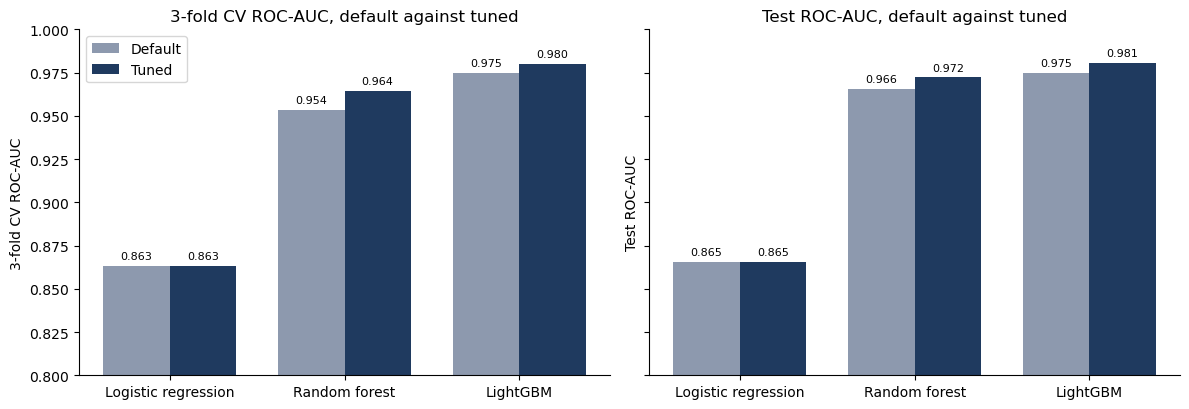

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
models = ["Logistic regression", "Random forest", "LightGBM"]
x = np.arange(len(models))
for ax, col, title in zip(axes, ["cv3_roc_auc_mean", "test_roc_auc"], ["3-fold CV ROC-AUC", "Test ROC-AUC"]):
    for j, (version, colour) in enumerate([("default", P["grey"]), ("tuned", P["navy"])]):
        vals = [before_after.query("model == @m and version == @version")[col].iloc[0] for m in models]
        ax.bar(x + (j - 0.5) * 0.38, vals, width=0.38, color=colour, label=version.capitalize())
        for xi, v in zip(x + (j - 0.5) * 0.38, vals):
            ax.text(xi, v + 0.004, f"{v:.3f}", ha="center", fontsize=8)
    ax.set_xticks(x, models)
    ax.set_ylim(0.8, 1.0)
    ax.set_ylabel(title)
    ax.set_title(f"{title}, default against tuned")
axes[0].legend()
fig.tight_layout()
save_fig(fig, "fig05_tuning_before_after.png")
plt.show()

Tuning helps the two tree ensembles and leaves the logistic regression where it was. LightGBM gains 0.0055 in CV ROC-AUC and 0.0059 on the test split (0.9748 to 0.9807), and its test PR-AUC rises from 0.9068 to 0.9262 while the Brier score falls from 0.0412 to 0.0351, so the tuned model both ranks and calibrates better. The tuned random forest (depth 16, 30% of features per split) improves from 0.9537 to 0.9641 in CV on the subsample and from 0.9656 to 0.9722 on the test split after the refit on the full training split, but it still trails LightGBM and took about three minutes to fit against 45 seconds. Refitting on all 716,761 loans was worth doing: the default forest scores 0.9578 on the test split when fitted on the 200,000-loan subsample (notebook 04) and 0.9656 when refitted on the full split. The ranking of notebook 04 is unchanged, so tuning confirms the choice of LightGBM rather than changing it.

## 4. Calibration of the tuned LightGBM

The cost matrix multiplies the predicted probability of default by money, so a probability of 0.20 must mean that about one loan in five with that score defaults. We compare the tuned LightGBM with an isotonic-calibrated version (`CalibratedClassifierCV`, three internal folds), which learns a monotone correction of the scores. Before looking at the result we fix the rule: we adopt calibration only if it lowers the test Brier score by at least 1% without lowering the test ROC-AUC by more than 0.001, because a calibrated wrapper makes the model larger and its SHAP explanations indirect.

In [8]:
start = time.time()
tuned_pipe = fitted[("LightGBM", "tuned")]
p_raw = tuned_pipe.predict_proba(X_test)[:, 1]
cal_pipe = md.make_pipeline(CalibratedClassifierCV(lgbm(**best_lgbm), method="isotonic", cv=3), NUM, CAT)
cal_pipe.fit(X_train[FEATURES], y_train)
p_cal = cal_pipe.predict_proba(X_test)[:, 1]
TIMINGS["calibration_minutes"] = (time.time() - start) / 60

calib = pd.DataFrame({
    "model": ["Tuned LightGBM", "Tuned LightGBM, isotonic calibration"],
    "test_roc_auc": [roc_auc_score(y_test, p_raw), roc_auc_score(y_test, p_cal)],
    "test_pr_auc": [average_precision_score(y_test, p_raw), average_precision_score(y_test, p_cal)],
    "test_brier": [brier_score_loss(y_test, p_raw), brier_score_loss(y_test, p_cal)],
    "mean_predicted_pd": [p_raw.mean(), p_cal.mean()],
})
use_calibration = bool(calib.loc[1, "test_brier"] <= 0.99 * calib.loc[0, "test_brier"]
                       and calib.loc[1, "test_roc_auc"] >= calib.loc[0, "test_roc_auc"] - 0.001)
print(f"Actual test default rate {y_test.mean():.4f}")
print("Use isotonic calibration:", use_calibration)
calib.round(5)

Actual test default rate 0.1757
Use isotonic calibration: False


,model,test_roc_auc,test_pr_auc,test_brier,mean_predicted_pd
0,Tuned LightGBM,0.98069,0.92619,0.03515,0.17571
1,"Tuned LightGBM, isotonic calibration",0.97958,0.92244,0.03717,0.17245


The calibration curve plots, for twenty equal-sized groups of test loans, the mean predicted probability against the observed default rate.

Saved docs/figures/fig05_calibration_curve.png


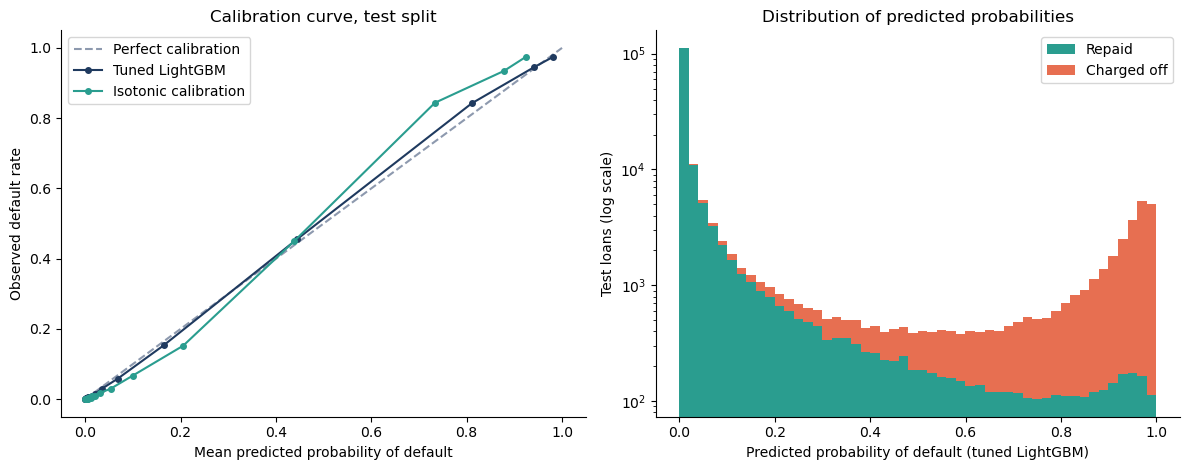

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
axes[0].plot([0, 1], [0, 1], linestyle="--", color=P["grey"], label="Perfect calibration")
for p, label, colour in [(p_raw, "Tuned LightGBM", P["navy"]), (p_cal, "Isotonic calibration", P["teal"])]:
    frac, mean_pred = calibration_curve(y_test, p, n_bins=20, strategy="quantile")
    axes[0].plot(mean_pred, frac, marker="o", markersize=4, color=colour, label=label)
axes[0].set_xlabel("Mean predicted probability of default")
axes[0].set_ylabel("Observed default rate")
axes[0].set_title("Calibration curve, test split")
axes[0].legend()
axes[1].hist([p_raw[y_test.to_numpy() == 0], p_raw[y_test.to_numpy() == 1]], bins=50, stacked=True,
             color=[P["teal"], P["red"]], label=["Repaid", "Charged off"])
axes[1].set_yscale("log")
axes[1].set_xlabel("Predicted probability of default (tuned LightGBM)")
axes[1].set_ylabel("Test loans (log scale)")
axes[1].set_title("Distribution of predicted probabilities")
axes[1].legend()
fig.tight_layout()
save_fig(fig, "fig05_calibration_curve.png")
plt.show()

The tuned LightGBM is already well calibrated: its mean predicted probability on the test split (0.1757) equals the observed default rate (0.1757), and its calibration curve follows the diagonal closely, with a slight underestimate in the 0.6 to 0.9 region where few loans fall. Isotonic calibration makes things worse on both counts: the Brier score rises from 0.0352 to 0.0372 and ROC-AUC falls from 0.9807 to 0.9796, because each of the three internal models is trained on only two thirds of the data and the step-shaped isotonic mapping creates ties between loans. Under our rule calibration is not adopted, and the final model is the tuned LightGBM itself. The histogram on the right shows why the model is useful to a bank: most repaid loans receive a probability close to zero and most charged-off loans a probability close to one, with comparatively few loans in between.

In [10]:
# The final model and the comparison model from here on
final_pipe = cal_pipe if use_calibration else tuned_pipe
comparison_pipe = fitted[("Logistic regression", "tuned")]
p_test = p_cal if use_calibration else p_raw
p_test_lr = comparison_pipe.predict_proba(X_test)[:, 1]
print("Final model:", "isotonic-calibrated LightGBM" if use_calibration else "tuned LightGBM without calibration")

Final model: tuned LightGBM without calibration


## 5. Choosing the decision threshold from the cost matrix

The bank approves a loan when its predicted probability of default is below a threshold. A low threshold declines many good borrowers and forgoes their interest; a high one lets through loans that will be charged off. For every threshold from 0.01 to 0.99 we compute the approval rate, the default rate among approved loans and the portfolio net value: 5% of the disbursed amount for each approved loan that is repaid, minus 50% of the unguaranteed principal plus 5% workout cost for each approved loan that defaults. Declined (and referred) loans count as zero, which is conservative because some referred loans would be approved after review.

To keep the test split clean we choose the threshold on out-of-fold predictions for the training loans: the tuned model is refitted on two of the three tuning folds and predicts the third, so every training loan gets a score from a model that has not seen it. We pick the threshold with the highest net value among those that approve at least 75% of loans (`config.MIN_APPROVAL_RATE`), and then report its results on the test split. The logistic comparison model gets its own threshold by the same rule.

In [11]:
start = time.time()
oof = cross_val_predict(clone(final_pipe), X_train[FEATURES], y_train, cv=FOLDS3, method="predict_proba")[:, 1]
oof_lr = cross_val_predict(clone(comparison_pipe), X_train[FEATURES], y_train, cv=FOLDS3, method="predict_proba")[:, 1]
TIMINGS["out_of_fold_minutes"] = (time.time() - start) / 60
print(f"Out-of-fold ROC-AUC on the training split: LightGBM {roc_auc_score(y_train, oof):.4f}, "
      f"logistic {roc_auc_score(y_train, oof_lr):.4f}")

sweep_train = ev.threshold_sweep(oof, y_train, D_train, G_train)
sweep_train_lr = ev.threshold_sweep(oof_lr, y_train, D_train, G_train)
THRESHOLD = ev.choose_threshold(sweep_train)
THRESHOLD_LR = ev.choose_threshold(sweep_train_lr)
best_unconstrained = float(sweep_train.loc[sweep_train["net_value"].idxmax(), "threshold"])
print(f"Chosen LightGBM threshold {THRESHOLD:.2f} (unconstrained optimum {best_unconstrained:.2f}); "
      f"logistic threshold {THRESHOLD_LR:.2f}")

sweep_test = ev.threshold_sweep(p_test, y_test, D_test, G_test)
sweep_out = sweep_train.add_prefix("train_oof_").rename(columns={"train_oof_threshold": "threshold"}).merge(
    sweep_test.add_prefix("test_").rename(columns={"test_threshold": "threshold"}), on="threshold")
sweep_out.round(6).to_csv(config.DOCS_DIR / "threshold_sweep.csv", index=False)
print("Saved docs/threshold_sweep.csv")
sweep_test[sweep_test["threshold"].isin([0.05, 0.10, THRESHOLD, 0.30, 0.50])].round(4)

Out-of-fold ROC-AUC on the training split: LightGBM 0.9802, logistic 0.8632


Chosen LightGBM threshold 0.22 (unconstrained optimum 0.22); logistic threshold 0.62


Saved docs/threshold_sweep.csv


,threshold,approval_rate,default_rate_approved,expected_default_rate_approved,net_value,expected_net_value,chargeoff_loss,recall_defaults
4,0.05,0.7054,0.0064,0.0078,1.323580e+09,1.319381e+09,3.178426e+07,0.9744
9,0.10,0.7509,0.0097,0.0116,1.384439e+09,1.375291e+09,5.027724e+07,0.9587
21,0.22,0.7919,0.0164,0.0188,1.413490e+09,1.399890e+09,9.443241e+07,0.9263
29,0.30,0.8068,0.0205,0.0233,1.406537e+09,1.391800e+09,1.273027e+08,0.9056
49,0.50,0.8323,0.0321,0.0346,1.350169e+09,1.340562e+09,2.179250e+08,0.8481


The three panels show how net value, approval rate and the default rate among approved loans move with the threshold on the test split. The dashed line marks the chosen threshold and the shaded area the thresholds that break the 75% approval rule.

Saved docs/figures/fig05_threshold_sweep.png


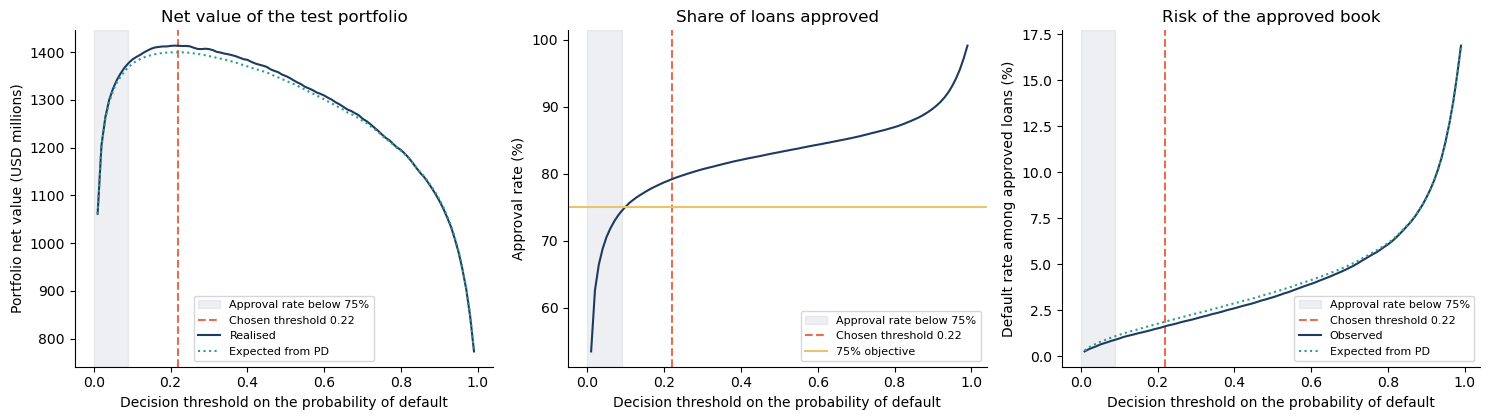

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
t = sweep_test["threshold"]
blocked = sweep_test.loc[sweep_test["approval_rate"] < config.MIN_APPROVAL_RATE, "threshold"]
for ax in axes:
    if len(blocked):
        ax.axvspan(0, blocked.max(), color=P["grey"], alpha=0.15, label="Approval rate below 75%")
    ax.axvline(THRESHOLD, color=P["red"], linestyle="--", label=f"Chosen threshold {THRESHOLD:.2f}")
    ax.set_xlabel("Decision threshold on the probability of default")
axes[0].plot(t, sweep_test["net_value"] / 1e6, color=P["navy"], label="Realised")
axes[0].plot(t, sweep_test["expected_net_value"] / 1e6, color=P["teal"], linestyle=":", label="Expected from PD")
axes[0].set_ylabel("Portfolio net value (USD millions)")
axes[0].set_title("Net value of the test portfolio")
axes[1].plot(t, 100 * sweep_test["approval_rate"], color=P["navy"])
axes[1].axhline(100 * config.MIN_APPROVAL_RATE, color=P["amber"], linestyle="-", label="75% objective")
axes[1].set_ylabel("Approval rate (%)")
axes[1].set_title("Share of loans approved")
axes[2].plot(t, 100 * sweep_test["default_rate_approved"], color=P["navy"], label="Observed")
axes[2].plot(t, 100 * sweep_test["expected_default_rate_approved"], color=P["teal"], linestyle=":", label="Expected from PD")
axes[2].set_ylabel("Default rate among approved loans (%)")
axes[2].set_title("Risk of the approved book")
for ax in axes:
    ax.legend(fontsize=8)
fig.tight_layout()
save_fig(fig, "fig05_threshold_sweep.png")
plt.show()

On the out-of-fold training predictions the net value peaks at a threshold of 0.22, and the same threshold is the best without the approval-rate rule, so the 75% constraint does not bind: the most profitable policy already approves enough loans. On the test split the curve is flat around the optimum (net value stays within about USD 7 million of its peak between 0.15 and 0.30), so small changes to the cost assumptions would not move the decision much. Below a threshold of 0.10 the approval rate drops under 75%, and net value falls quickly because many good loans are turned away. The expected values computed from the model's probabilities (dotted lines) follow the realised values closely, which is the practical benefit of a well-calibrated model: the app can quote an expected default rate and expected net value that the bank would actually see. The threshold of 0.22 is close to the break-even probability for a loan with a 75% guarantee (0.222) found in notebook 04, as the cost matrix predicts.

### 5.1 Model policy against approve-all and against the logistic comparison model

We now apply the three policies to the 179,191 test loans and count what actually happened: interest earned on approved loans that were repaid, losses on approved loans that were charged off, and the interest forgone on good loans that were turned away. This is SMART objective 2: at least 25% less charge-off loss than approving everything, at an approval rate of at least 75%.

In [13]:
ones = np.ones(len(y_test), dtype=bool)
policies = {
    "Approve all": ev.policy_summary(ones, y_test, D_test, G_test, np.full(len(y_test), y_train.mean())),
    f"LightGBM, threshold {THRESHOLD:.2f}": ev.policy_summary(p_test < THRESHOLD, y_test, D_test, G_test, p_test),
    f"Logistic regression, threshold {THRESHOLD_LR:.2f}": ev.policy_summary(p_test_lr < THRESHOLD_LR, y_test, D_test,
                                                                             G_test, p_test_lr),
}
policy = pd.DataFrame(policies).T
base_loss = policy.loc["Approve all", "chargeoff_loss"]
base_value = policy.loc["Approve all", "net_value"]
policy["loss_avoided"] = base_loss - policy["chargeoff_loss"]
policy["loss_reduction_pct"] = 100 * policy["loss_avoided"] / base_loss
policy["net_value_gain_vs_approve_all"] = policy["net_value"] - base_value
policy.index.name = "policy"
policy.round(4).to_csv(config.DOCS_DIR / "policy_comparison.csv")
print("Saved docs/policy_comparison.csv")
model_key, lr_key = list(policies)[1], list(policies)[2]
m = policy.loc[model_key]
print(f"LightGBM policy: approval rate {m.approval_rate:.1%}, default rate among approved {m.default_rate_approved:.2%}, "
      f"net value {usd_m(m.net_value)} against {usd_m(base_value)} for approve-all, "
      f"charge-off loss down {m.loss_reduction_pct:.1f}%")
display_cols = ["approval_rate", "default_rate_approved", "net_value", "chargeoff_loss", "interest_forgone",
                "loss_avoided", "loss_reduction_pct", "net_value_gain_vs_approve_all"]
policy[display_cols].style.format({"approval_rate": "{:.1%}", "default_rate_approved": "{:.2%}",
                                   "loss_reduction_pct": "{:.1f}%", **{c: "{:,.0f}" for c in
                                   ["net_value", "chargeoff_loss", "interest_forgone", "loss_avoided",
                                    "net_value_gain_vs_approve_all"]}})

Saved docs/policy_comparison.csv
LightGBM policy: approval rate 79.2%, default rate among approved 1.64%, net value USD 1,413.5 m against USD 733.7 m for approve-all, charge-off loss down 89.1%


,approval_rate,default_rate_approved,net_value,chargeoff_loss,interest_forgone,loss_avoided,loss_reduction_pct,net_value_gain_vs_approve_all
policy,,,,,,,,
Approve all,100.0%,17.57%,"733,716,876","864,435,432",0,0,0.0%,0
"LightGBM, threshold 0.22",79.2%,1.64%,"1,413,490,191","94,432,413","90,229,705","770,003,020",89.1%,"679,773,315"
"Logistic regression, threshold 0.62",77.4%,6.52%,"1,094,606,844","327,143,018","176,402,447","537,292,415",62.2%,"360,889,968"


The chart puts the three policies side by side in money terms.

Saved docs/figures/fig05_policy_comparison.png


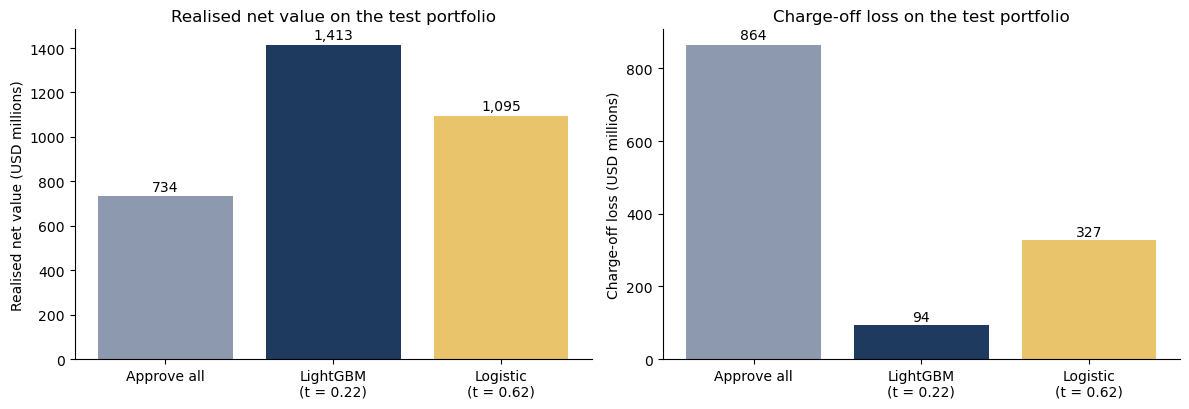

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
labels = ["Approve all", f"LightGBM\n(t = {THRESHOLD:.2f})", f"Logistic\n(t = {THRESHOLD_LR:.2f})"]
colours = [P["grey"], P["navy"], P["amber"]]
for ax, col, title in zip(axes, ["net_value", "chargeoff_loss"], ["Realised net value", "Charge-off loss"]):
    vals = policy[col].to_numpy() / 1e6
    ax.bar(labels, vals, color=colours)
    for i, v in enumerate(vals):
        ax.text(i, v * 1.01, f"{v:,.0f}", ha="center", va="bottom")
    ax.set_ylabel(f"{title} (USD millions)")
    ax.set_title(f"{title} on the test portfolio")
fig.tight_layout()
save_fig(fig, "fig05_policy_comparison.png")
plt.show()

On the test portfolio the LightGBM policy approves 79.2% of loans, and only 1.64% of the approved loans default, against 17.57% if every loan is approved. Charge-off loss falls from USD 864.4 million to USD 94.4 million, a reduction of 89.1%, which is far beyond the 25% target of SMART objective 2 at an approval rate above 75%. The cost is USD 90.2 million of interest forgone on repaid loans that were not approved, so the net value of the book almost doubles, from USD 733.7 million to USD 1,413.5 million. The logistic comparison model, at its own cost-based threshold of 0.62, approves 77.4% of loans with a default rate of 6.52% among them; it reduces the loss by 62.2% and earns USD 1,094.6 million, which shows that even the simple model is worth having, but that the tree model's better ranking is worth about USD 319 million on this portfolio. These figures assume that referred loans are not approved, and they inherit the limitations of the data discussed in sections 9 and 10.

## 6. Final evaluation of the tuned LightGBM on the test split

At the chosen threshold, a prediction of "default" means the loan is not approved automatically (it is referred or declined). The confusion matrix counts the four outcomes, and the classification report gives precision, recall and F1 for both classes.

In [15]:
metrics_test = ev.classification_metrics(y_test, p_test, THRESHOLD)
metrics_test_lr = ev.classification_metrics(y_test, p_test_lr, THRESHOLD_LR)
pred_test = (p_test >= THRESHOLD).astype(int)
cm = confusion_matrix(y_test, pred_test)
print(pd.DataFrame({"LightGBM": metrics_test, "Logistic regression": metrics_test_lr}).round(4).to_string())
print()
print(classification_report(y_test, pred_test, target_names=["Repaid (0)", "Charged off (1)"], digits=4))
print(f"SMART objective 1: ROC-AUC {metrics_test['roc_auc']:.4f} (target 0.80), "
      f"recall {metrics_test['recall']:.4f} (target 0.70)")

                   LightGBM  Logistic regression
roc_auc              0.9807               0.8655
pr_auc               0.9262               0.6276
f1                   0.8479               0.6234
precision            0.7817               0.5539
recall               0.9263               0.7127
brier                0.0351               0.1513
accuracy             0.9416               0.8487
balanced_accuracy    0.9356               0.7952

                 precision    recall  f1-score   support

     Repaid (0)     0.9836    0.9449    0.9639    147716
Charged off (1)     0.7817    0.9263    0.8479     31475

       accuracy                         0.9416    179191
      macro avg     0.8827    0.9356    0.9059    179191
   weighted avg     0.9482    0.9416    0.9435    179191

SMART objective 1: ROC-AUC 0.9807 (target 0.80), recall 0.9263 (target 0.70)


The confusion matrix is shown as counts and as a share of each actual class.

Saved docs/figures/fig05_confusion_matrix.png


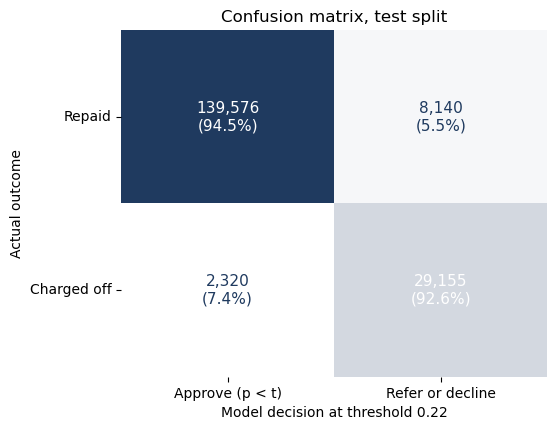

In [16]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
cmap = LinearSegmentedColormap.from_list("house", ["#FFFFFF", P["navy"]])
sns.heatmap(cm, annot=False, cmap=cmap, cbar=False, ax=ax)
row_share = cm / cm.sum(axis=1, keepdims=True)
for i in range(2):
    for j in range(2):
        ax.text(j + 0.5, i + 0.5, f"{cm[i, j]:,}\n({row_share[i, j]:.1%})", ha="center", va="center",
                color="white" if row_share[i, j] > 0.5 else P["navy"], fontsize=11)
ax.set_xticklabels(["Approve (p < t)", "Refer or decline"])
ax.set_yticklabels(["Repaid", "Charged off"], rotation=0)
ax.set_xlabel(f"Model decision at threshold {THRESHOLD:.2f}")
ax.set_ylabel("Actual outcome")
ax.set_title("Confusion matrix, test split")
save_fig(fig, "fig05_confusion_matrix.png")
plt.show()

At the threshold of 0.22 the model refers or declines 92.6% of the loans that were later charged off (recall 0.9263, against the target of 0.70) and only 5.5% of the loans that were repaid. Of the loans it does not approve automatically, 78.2% actually defaulted (precision 0.7817). Both parts of SMART objective 1 are met with a wide margin: test ROC-AUC 0.9807 against a target of 0.80 and recall 0.926 against 0.70. The 2,320 false negatives (approved loans that defaulted) are the costly errors and are examined in section 9.1.

## 7. Risk bands and the decision rule

A single threshold gives a yes or no; a credit desk also needs to know how far a loan is from the line. We define four bands on the probability of default. The boundary between Medium and High is the business threshold, so every Low or Medium loan is approved. The Low band ends at 0.10, and High ends at 0.50, above which a loan is more likely than not to default.

The decision rule follows the bands: approve Low and Medium, refer High to manual review, decline Very high.

In [17]:
LOW_CUT = 0.10 if THRESHOLD > 0.10 else round(THRESHOLD / 2, 2)
HIGH_CUT = 0.50 if THRESHOLD < 0.50 else round(min(THRESHOLD + 0.20, 0.90), 2)
RISK_BANDS = [
    {"name": "Low", "min": 0.0, "max": LOW_CUT},
    {"name": "Medium", "min": LOW_CUT, "max": THRESHOLD},
    {"name": "High", "min": THRESHOLD, "max": HIGH_CUT},
    {"name": "Very high", "min": HIGH_CUT, "max": 1.0},
]
DECISION_RULE = (f"Approve when the probability of default is below {THRESHOLD:.2f} (Low and Medium bands); "
                 f"refer to manual review when it is from {THRESHOLD:.2f} to below {HIGH_CUT:.2f} (High band); "
                 f"decline when it is {HIGH_CUT:.2f} or more (Very high band).")
print(DECISION_RULE)

band_test = pd.Series(ev.assign_band(p_test, RISK_BANDS), index=X_test.index, name="band")
band_names = [b["name"] for b in RISK_BANDS]
bands = (pd.DataFrame({"band": band_test, "default": y_test, "pd": p_test, "disbursed": D_test})
         .groupby("band").agg(loans=("default", "size"), defaults=("default", "sum"),
                              default_rate=("default", "mean"), mean_predicted_pd=("pd", "mean"),
                              disbursed_usd=("disbursed", "sum")).reindex(band_names))
bands["share_of_loans"] = bands["loans"] / bands["loans"].sum()
bands["share_of_defaults"] = bands["defaults"] / bands["defaults"].sum()
bands.insert(0, "pd_min", [b["min"] for b in RISK_BANDS])
bands.insert(1, "pd_max", [b["max"] for b in RISK_BANDS])
bands.insert(2, "decision", ["Approve", "Approve", "Refer", "Decline"])
bands.round(4).to_csv(config.DOCS_DIR / "risk_bands.csv")
print("Saved docs/risk_bands.csv")
bands.round(4)

Approve when the probability of default is below 0.22 (Low and Medium bands); refer to manual review when it is from 0.22 to below 0.50 (High band); decline when it is 0.50 or more (Very high band).
Saved docs/risk_bands.csv


,pd_min,pd_max,decision,loans,defaults,default_rate,mean_predicted_pd,disbursed_usd,share_of_loans,share_of_defaults
band,,,,,,,,,,
Low,0.00,0.10,Approve,134554,1300,0.0097,0.0116,2.896017e+10,0.7509,0.0413
Medium,0.10,0.22,Approve,7342,1020,0.1389,0.1507,1.700330e+09,0.0410,0.0324
High,0.22,0.50,Refer,7251,2462,0.3395,0.3440,1.858935e+09,0.0405,0.0782
Very high,0.50,1.00,Decline,30044,26693,0.8885,0.8760,3.596184e+09,0.1677,0.8481


The chart shows each band's share of loans and its observed default rate.

Saved docs/figures/fig05_risk_bands.png


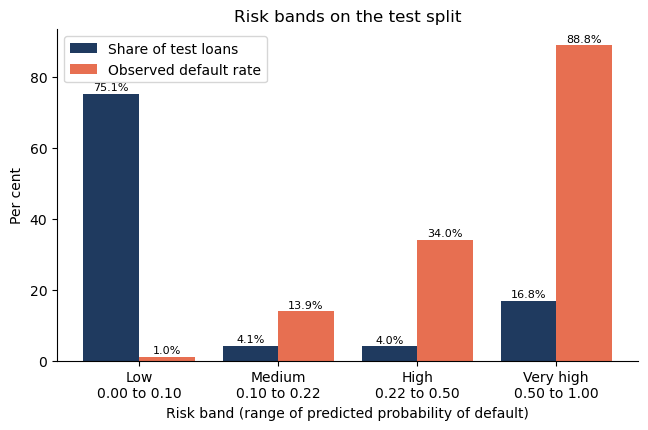

In [18]:
fig, ax1 = plt.subplots(figsize=(7.5, 4.3))
x = np.arange(len(band_names))
ax1.bar(x - 0.2, 100 * bands["share_of_loans"], width=0.4, color=P["navy"], label="Share of test loans")
ax1.bar(x + 0.2, 100 * bands["default_rate"], width=0.4, color=P["red"], label="Observed default rate")
for xi, s, d in zip(x, bands["share_of_loans"], bands["default_rate"]):
    ax1.text(xi - 0.2, 100 * s + 1, f"{100 * s:.1f}%", ha="center", fontsize=8)
    ax1.text(xi + 0.2, 100 * d + 1, f"{100 * d:.1f}%", ha="center", fontsize=8)
ax1.set_xticks(x, [f"{b['name']}\n{b['min']:.2f} to {b['max']:.2f}" for b in RISK_BANDS])
ax1.set_xlabel("Risk band (range of predicted probability of default)")
ax1.set_ylabel("Per cent")
ax1.set_title("Risk bands on the test split")
ax1.legend()
save_fig(fig, "fig05_risk_bands.png")
plt.show()

The bands separate risk sharply. Three loans in four (75.1%) fall in the Low band, where only 1.0% default; these can be approved with light checks. The Medium band (4.1% of loans, 13.9% default) is still approved but deserves the standard file review. The High band holds 4.0% of loans, of which 34.0% default; these are referred to a credit officer, who can look for collateral, a larger guarantee or a shorter exposure. The Very high band (16.8% of loans) defaults at 88.8% and contains 84.8% of all defaults, so declining it removes most of the loss. In every band the mean predicted probability is within about 2 percentage points of the observed default rate, so the band labels mean what they say.

## 8. Explaining the model

### 8.1 SHAP values for the final LightGBM

SHAP splits each prediction into contributions from the features: starting from the average log-odds of default over the training data, each feature pushes the score up (towards default) or down. `TreeExplainer` computes these values exactly for tree models. We explain a stratified sample of 5,000 test loans in the preprocessed form the classifier sees, in which each categorical feature is a single coded column, so every SHAP value belongs to one original feature. Values are on the log-odds scale.

In [19]:
start = time.time()
shap_pipe = tuned_pipe  # SHAP explains the tuned LightGBM itself
prep = shap_pipe.named_steps["prep"]
lgbm_model = shap_pipe.named_steps["clf"]
feature_names = list(prep.get_feature_names_out())

X_explain, y_explain = md.stratified_subsample(X_test, y_test, 5_000)
X_explain_t = pd.DataFrame(prep.transform(X_explain[FEATURES]), columns=feature_names, index=X_explain.index)
explainer = shap.TreeExplainer(lgbm_model)
sv = explainer(X_explain_t)
TIMINGS["shap_seconds"] = time.time() - start
p_explain = shap_pipe.predict_proba(X_explain[FEATURES])[:, 1]
check = 1 / (1 + np.exp(-(sv.values.sum(axis=1) + sv.base_values)))
print(f"SHAP values for {len(X_explain_t):,} loans and {len(feature_names)} features in {TIMINGS['shap_seconds']:.1f} s")
print(f"Largest gap between SHAP sum and model probability: {np.abs(check - p_explain).max():.2e}")

shap_global = (pd.DataFrame({"feature": feature_names, "mean_abs_shap": np.abs(sv.values).mean(axis=0)})
               .sort_values("mean_abs_shap", ascending=False).reset_index(drop=True))
shap_global["share_of_total"] = shap_global["mean_abs_shap"] / shap_global["mean_abs_shap"].sum()
shap_global.round(5)

SHAP values for 5,000 loans and 24 features in 24.5 s
Largest gap between SHAP sum and model probability: 2.35e-14


,feature,mean_abs_shap,share_of_total
0,TermYears,2.17786,0.40780
1,BankDefaultRate,0.59548,0.11150
2,Portion,0.42869,0.08027
3,Sector,0.23350,0.04372
4,RealEstate,0.22290,0.04174
5,LogDisbursement,0.18033,0.03377
6,BankSize,0.15995,0.02995
7,SameStateBank,0.15305,0.02866
8,BankState,0.13646,0.02555
9,Recession,0.12747,0.02387


The beeswarm plot shows one dot per loan and feature: its horizontal position is the SHAP value and its colour the feature value (teal low, red high). For the coded categorical features the colour is only a category code and should not be read as low or high.

Saved docs/figures/fig05_shap_beeswarm.png


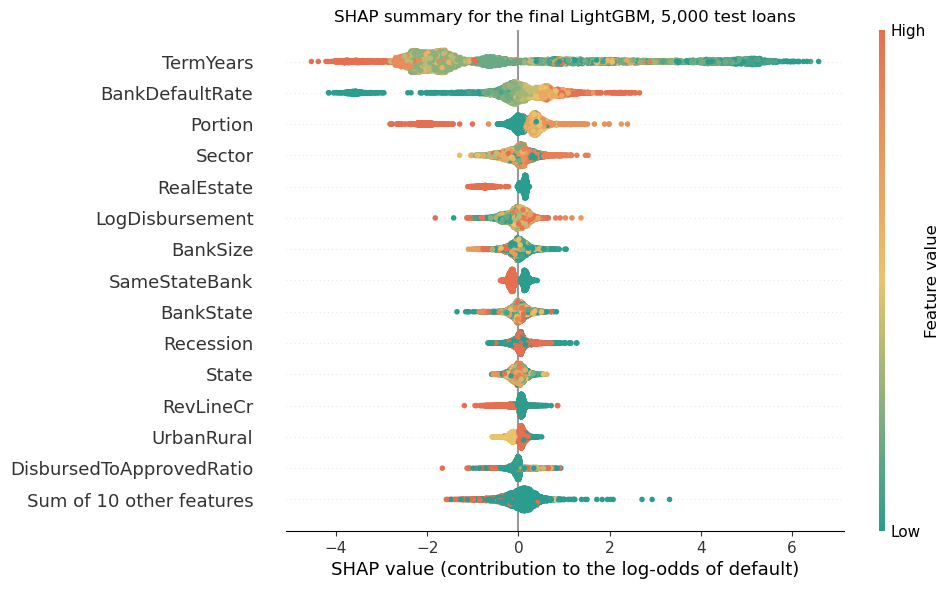

In [20]:
house_cmap = LinearSegmentedColormap.from_list("house", [P["teal"], P["amber"], P["red"]])
plt.figure()
shap.plots.beeswarm(sv, max_display=15, show=False, color=house_cmap, plot_size=(9, 6.5))
fig = plt.gcf()
ax = plt.gca()
ax.set_xlabel("SHAP value (contribution to the log-odds of default)")
ax.set_title("SHAP summary for the final LightGBM, 5,000 test loans")
save_fig(fig, "fig05_shap_beeswarm.png")
plt.show()

Term dominates: short terms (teal, on the left of the colour scale) push the log-odds of default up by as much as 6, and long terms push it down by 2 to 4. The lender's historical default rate comes next, with a low rate lowering the risk sharply and a high rate raising it, followed by the guaranteed share, where high shares lower the score. Loans from a bank in the same state (red for `SameStateBank`) and real-estate loans (red for `RealEstate`) are scored as safer, and being active during the recession (red for `Recession`) raises the score, which is the behaviour the app's stress-scenario switch relies on. For the coded categorical features (`Sector`, `BankState`, `State`, `RevLineCr`, `UrbanRural`) the spread of the dots matters, not their colour.

The bar chart ranks the features by mean absolute SHAP value, the average size of their push on a prediction.

Saved docs/figures/fig05_shap_importance_bar.png


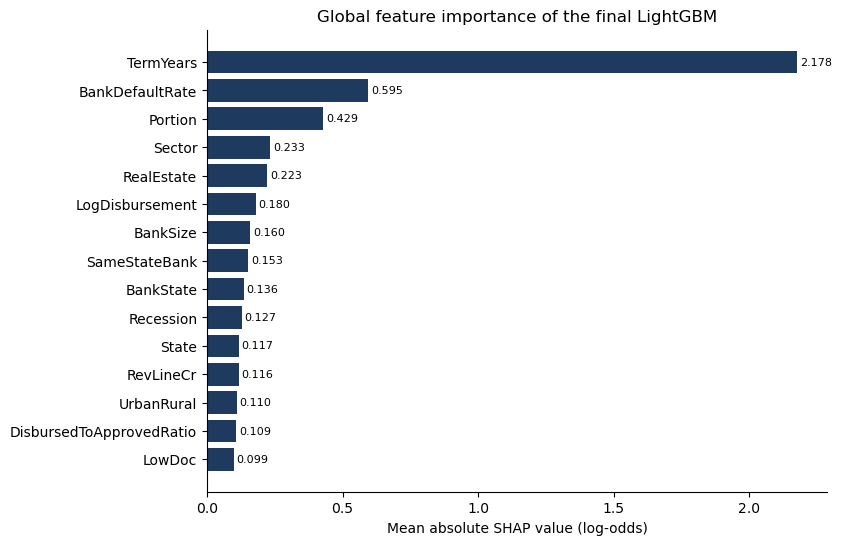

In [21]:
top15 = shap_global.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top15["feature"], top15["mean_abs_shap"], color=P["navy"])
for y_pos, v in enumerate(top15["mean_abs_shap"]):
    ax.text(v + 0.01, y_pos, f"{v:.3f}", va="center", fontsize=8)
ax.set_xlabel("Mean absolute SHAP value (log-odds)")
ax.set_title("Global feature importance of the final LightGBM")
save_fig(fig, "fig05_shap_importance_bar.png")
plt.show()

Dependence plots show, for the three most important numeric features, how the SHAP value changes with the feature value. Each dot is a loan; the colour shows whether it defaulted.

Saved docs/figures/fig05_shap_dependence.png


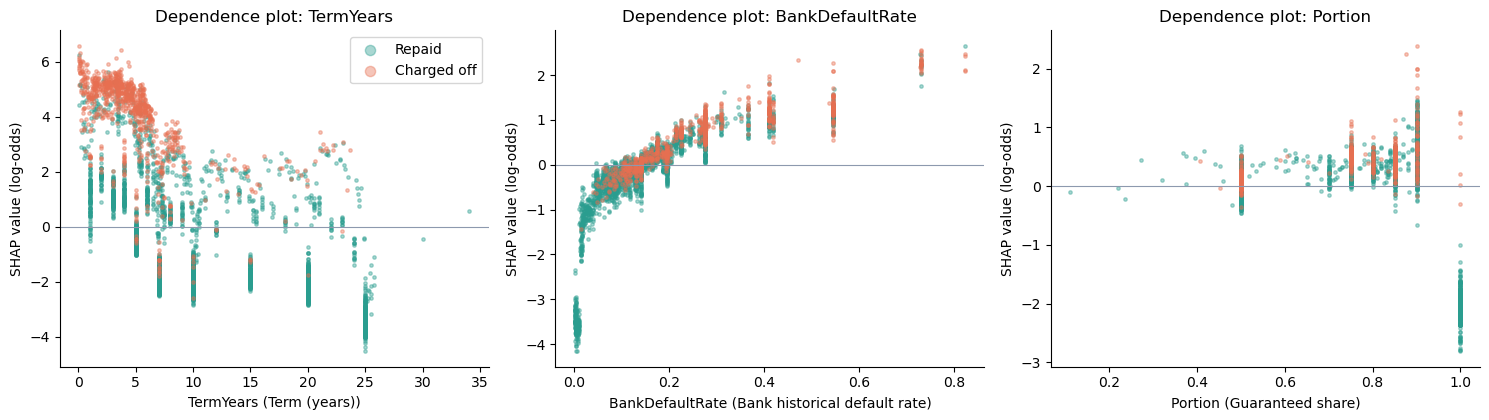

Features shown: ['TermYears', 'BankDefaultRate', 'Portion']


In [22]:
numeric_rank = [f for f in shap_global["feature"] if f not in CAT][:3]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, feat in zip(axes, numeric_rank):
    j = feature_names.index(feat)
    xv = X_explain_t[feat].to_numpy()
    for outcome, colour, label in [(0, P["teal"], "Repaid"), (1, P["red"], "Charged off")]:
        mask = y_explain.to_numpy() == outcome
        ax.scatter(xv[mask], sv.values[mask, j], s=6, alpha=0.4, color=colour, label=label)
    ax.axhline(0, color=P["grey"], linewidth=0.8)
    if feat in ["BankSize", "LoanPerEmployee"]:
        ax.set_xscale("symlog")
    ax.set_xlabel(f"{feat} ({fe.FEATURE_INFO.get(feat, (feat, ''))[0]})")
    ax.set_ylabel("SHAP value (log-odds)")
    ax.set_title(f"Dependence plot: {feat}")
axes[0].legend(markerscale=3)
fig.tight_layout()
save_fig(fig, "fig05_shap_dependence.png")
plt.show()
print("Features shown:", numeric_rank)

The dependence plots show the shapes the model has learned. For term, loans of up to about five years carry SHAP values of 4 to 6, with a clear step down at five and seven years, and loans of 20 years or more fall to between -2 and -4; the large vertical spread at a given term shows that the effect of term depends on other features, such as the guarantee. The bank's default rate has an almost monotone effect, from about -4 for banks with a near-zero historical rate to above +2 for banks with rates above 0.7, flattening in the middle range. For the guaranteed share, the main effect is that loans with a 100% guarantee are much safer (SHAP between -2 and -3); between 50% and 90% the contribution stays close to zero or slightly positive, which matches notebook 03's finding that the share mostly reflects the loan programme.

### 8.2 Three individual explanations

The app shows a credit officer why a single loan received its score. We pick three loans from the explained sample: a clear approval (one of the lowest scores), a clear decline (one of the highest) and a borderline case (the score closest to the threshold). Each chart starts from the model's average log-odds and adds the ten largest feature contributions; the remaining features are grouped.

Saved docs/figures/fig05_shap_individual_cases.png


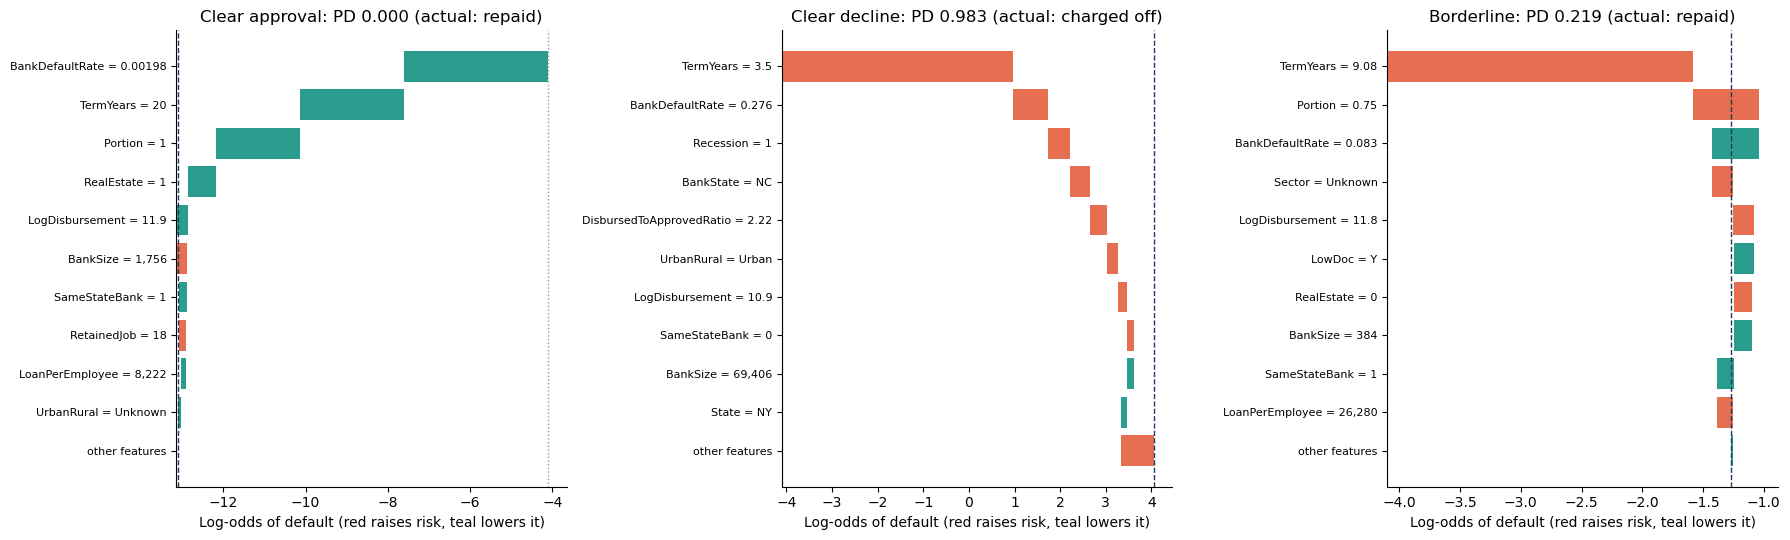

,case,loan_number,pd,band,actual_default,top_drivers
0,Clear approval,1318824010,0.000002,Low,0,BankDefaultRate -3.50; TermYears -2.53; Portio...
1,Clear decline,1776295010,0.982875,Very high,1,TermYears +5.06; BankDefaultRate +0.78; Recess...
2,Borderline,2811054002,0.219332,Medium,0,TermYears +2.52; Portion +0.54; BankDefaultRat...


In [23]:
order = np.argsort(p_explain)
cases = {
    "Clear approval": order[int(0.02 * len(order))],
    "Clear decline": order[int(0.98 * len(order))],
    "Borderline": int(np.argmin(np.abs(p_explain - THRESHOLD))),
}
raw_display = X_explain[FEATURES].copy()
raw_display["BankSize"] = X_explain_t["BankSize"]
raw_display["BankDefaultRate"] = X_explain_t["BankDefaultRate"]


def fmt_value(v):
    """Short text for a feature value in the explanation charts."""
    if isinstance(v, (int, np.integer)):
        return f"{v:,}"
    if isinstance(v, (float, np.floating)):
        return f"{v:,.3g}" if abs(v) < 1000 else f"{v:,.0f}"
    return str(v)


fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
case_rows = []
for ax, (case, i) in zip(axes, cases.items()):
    contrib = pd.Series(sv.values[i], index=feature_names)
    top = contrib.reindex(contrib.abs().sort_values(ascending=False).index[:10])
    rest = contrib.drop(top.index).sum()
    labels = [f"{f} = {fmt_value(raw_display.iloc[i][f])}" for f in top.index] + ["other features"]
    values = list(top.values) + [rest]
    base = float(sv.base_values[i])
    lefts, running = [], base
    for v in values:
        lefts.append(running if v >= 0 else running + v)
        running += v
    ypos = np.arange(len(values))[::-1]
    ax.barh(ypos, np.abs(values), left=lefts, color=[P["red"] if v > 0 else P["teal"] for v in values])
    ax.set_yticks(ypos, labels, fontsize=8)
    ax.axvline(base, color=P["grey"], linestyle=":", linewidth=1)
    ax.axvline(running, color=P["navy"], linestyle="--", linewidth=1)
    ax.set_xlabel("Log-odds of default (red raises risk, teal lowers it)")
    ax.set_title(f"{case}: PD {p_explain[i]:.3f} (actual: {'charged off' if y_explain.iloc[i] else 'repaid'})")
    case_rows.append({"case": case, "loan_number": int(X_explain.iloc[i]["LoanNr_ChkDgt"]), "pd": float(p_explain[i]),
                      "band": ev.assign_band([p_explain[i]], RISK_BANDS)[0], "actual_default": int(y_explain.iloc[i]),
                      "top_drivers": "; ".join(f"{f} {v:+.2f}" for f, v in top.head(3).items())})
fig.tight_layout()
save_fig(fig, "fig05_shap_individual_cases.png")
plt.show()
pd.DataFrame(case_rows)

The three explanations read as a credit officer would expect. The clear approval is a 20-year loan with a full guarantee from a bank whose past loans almost never defaulted; each of these facts lowers the risk, and the probability of default is effectively zero. The clear decline is a three-and-a-half-year loan from a large out-of-state lender with a high historical default rate, active during the recession and drawn at more than twice its approved amount; term alone adds about 5 to the log-odds, and the probability is 0.983. The borderline loan (probability 0.219, just under the threshold of 0.22 and therefore at the top of the Medium band) shows the trade-off the officer would weigh: a nine-year term and a 75% guarantee raise the risk, while a bank with a below-average default rate, LowDoc status and a lender in the same state lower it. It was repaid. In the app, such a loan would be approved, but with the drivers shown so that the officer can decide whether a closer look is needed.

### 8.3 Permutation importance for the logistic comparison model

For the logistic regression we use permutation importance: we shuffle one input column at a time in a stratified sample of 20,000 test loans and measure how much the test ROC-AUC falls. A large fall means the model relies on that feature. Unlike the coefficients, this works on the original 23 inputs, so it is directly comparable with the SHAP ranking.

Permutation importance in 11 s; saved docs/permutation_importance_logistic.csv


Saved docs/figures/fig05_permutation_importance_logistic.png


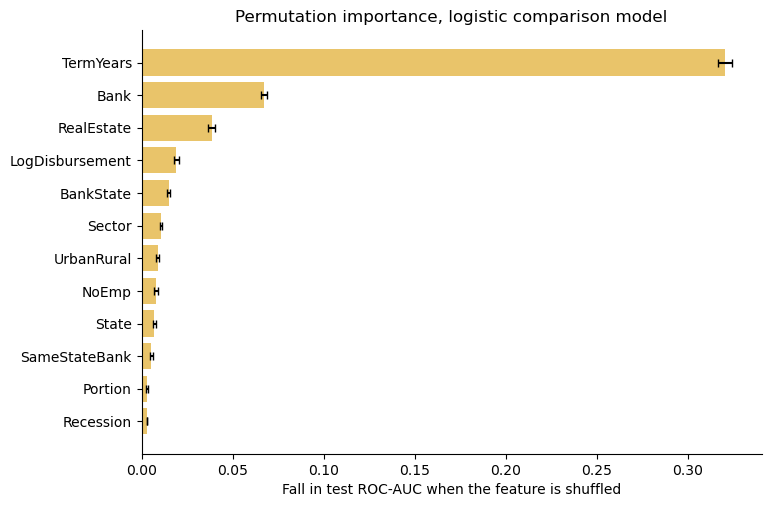

,feature,auc_drop_mean,auc_drop_std
0,TermYears,0.3202,0.0039
1,Bank,0.0673,0.0018
2,RealEstate,0.0384,0.0017
3,LogDisbursement,0.0191,0.0015
4,BankState,0.0148,0.0006
5,Sector,0.0109,0.0005
6,UrbanRural,0.0089,0.0007
7,NoEmp,0.0079,0.0010
8,State,0.0069,0.0009
9,SameStateBank,0.0054,0.0009


In [24]:
start = time.time()
X_perm, y_perm = md.stratified_subsample(X_test, y_test, 20_000)
perm = permutation_importance(comparison_pipe, X_perm[FEATURES], y_perm, scoring="roc_auc", n_repeats=5,
                              random_state=config.RANDOM_STATE, n_jobs=1)
perm_table = (pd.DataFrame({"feature": FEATURES, "auc_drop_mean": perm.importances_mean, "auc_drop_std": perm.importances_std})
              .sort_values("auc_drop_mean", ascending=False).reset_index(drop=True))
TIMINGS["permutation_seconds"] = time.time() - start
perm_table.round(4).to_csv(config.DOCS_DIR / "permutation_importance_logistic.csv", index=False)
print(f"Permutation importance in {TIMINGS['permutation_seconds']:.0f} s; saved docs/permutation_importance_logistic.csv")

top = perm_table.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top["feature"], top["auc_drop_mean"], xerr=top["auc_drop_std"], color=P["amber"], capsize=3)
ax.set_xlabel("Fall in test ROC-AUC when the feature is shuffled")
ax.set_title("Permutation importance, logistic comparison model")
save_fig(fig, "fig05_permutation_importance_logistic.png")
plt.show()
perm_table.head(10).round(4)

**The main drivers in plain English.** Both models agree on what matters most. The length of the loan comes first by a wide margin: short loans, typically working capital and revolving lines, are much riskier than long loans secured on property. Shuffling term costs the logistic regression 0.32 of ROC-AUC, five times more than any other input, and it accounts for 41% of the total SHAP importance of LightGBM. Next comes the lender: the bank's historical default rate and size (the encoded `Bank` column is the second most important input for the logistic regression and `BankDefaultRate` the second for LightGBM) capture differences in underwriting standards and product mix. Then come the size of the guarantee, the sector, whether the loan is secured on real estate, the loan amount (smaller loans are riskier), whether the bank is in the borrower's state, and the recession. The two models differ in how they use the guaranteed share: it is the third driver for LightGBM, which can isolate the safe 100% guaranteed loans, but outside the logistic model's top ten, because its effect is not a straight line. Business age, franchise status and job counts matter little once these are known.

## 9. Error analysis

An overall AUC can hide groups of loans where the model is weak or biased. For each sector, the ten states with most test loans, loan size bands, term bands and approval years we report the number of test loans, the observed default rate, the mean predicted probability, the ROC-AUC within the group and the recall at the business threshold. A large gap between observed and predicted rates means the model is miscalibrated for that group.

In [25]:
ea = X_test[["Sector", "State", "DisbursementGross", "Term", "ApprovalFY"]].copy()
ea["default"] = y_test.to_numpy()
ea["pd"] = p_test
ea["flagged"] = (p_test >= THRESHOLD).astype(int)
ea["Loan size band"] = pd.cut(ea["DisbursementGross"], [0, 25e3, 50e3, 150e3, 500e3, 1e6, np.inf],
                              labels=["<25k", "25k-50k", "50k-150k", "150k-500k", "500k-1m", ">1m"], right=False)
ea["Term band"] = pd.cut(ea["Term"], [0, 13, 37, 61, 85, 121, 181, 240, np.inf],
                         labels=["1-12", "13-36", "37-60", "61-84", "85-120", "121-180", "181-239", "240+"], right=False)
top_states = ea["State"].astype(str).value_counts().head(10).index
ea["Top 10 state"] = ea["State"].astype(str).where(ea["State"].astype(str).isin(top_states))
ea["Approval year"] = ea["ApprovalFY"].clip(lower=1988).astype(int).astype(str).replace("1988", "1988 or earlier")


def group_metrics(g):
    """Size, observed and predicted default rate, AUC and recall for one group."""
    auc = roc_auc_score(g["default"], g["pd"]) if g["default"].nunique() == 2 else np.nan
    rec = g.loc[g["default"] == 1, "flagged"].mean() if g["default"].sum() else np.nan
    return pd.Series({"loans": len(g), "observed_default_rate": g["default"].mean(),
                      "mean_predicted_pd": g["pd"].mean(), "roc_auc": auc, "recall_at_threshold": rec})


tables = []
for dim in ["Sector", "Top 10 state", "Loan size band", "Term band", "Approval year"]:
    t = ea.dropna(subset=[dim]).groupby(dim, observed=True)[["default", "pd", "flagged"]].apply(group_metrics)
    t = t.reset_index().rename(columns={dim: "group"})
    t.insert(0, "dimension", dim)
    tables.append(t)
error_table = pd.concat(tables, ignore_index=True)
error_table["gap_predicted_minus_observed"] = error_table["mean_predicted_pd"] - error_table["observed_default_rate"]
error_table.round(4).to_csv(config.DOCS_DIR / "error_analysis.csv", index=False)
print("Saved docs/error_analysis.csv")
error_table[error_table["dimension"] != "Approval year"].round(3)

Saved docs/error_analysis.csv


,dimension,group,loans,observed_default_rate,mean_predicted_pd,roc_auc,recall_at_threshold,gap_predicted_minus_observed
0,Sector,Accommodation and food services,13397.0,0.221,0.220,0.980,0.940,-0.002
1,Sector,Administrative and support and waste management,6491.0,0.232,0.237,0.986,0.968,0.005
2,Sector,"Agriculture, forestry, fishing and hunting",1766.0,0.090,0.092,0.973,0.881,0.002
3,Sector,"Arts, entertainment, and recreation",2834.0,0.186,0.189,0.975,0.911,0.004
4,Sector,Construction,13225.0,0.240,0.238,0.983,0.950,-0.002
5,Sector,Educational services,1279.0,0.233,0.238,0.980,0.950,0.005
6,Sector,Finance and insurance,1869.0,0.278,0.277,0.986,0.971,-0.001
7,Sector,Health care and social assistance,11113.0,0.105,0.105,0.979,0.896,-0.000
8,Sector,Information,2256.0,0.243,0.249,0.985,0.962,0.006
9,Sector,Management of companies and enterprises,48.0,0.083,0.079,0.989,0.750,-0.004


The four panels compare the observed default rate with the mean predicted probability in each group; the group AUC is printed beside each pair of bars.

Saved docs/figures/fig05_error_analysis.png


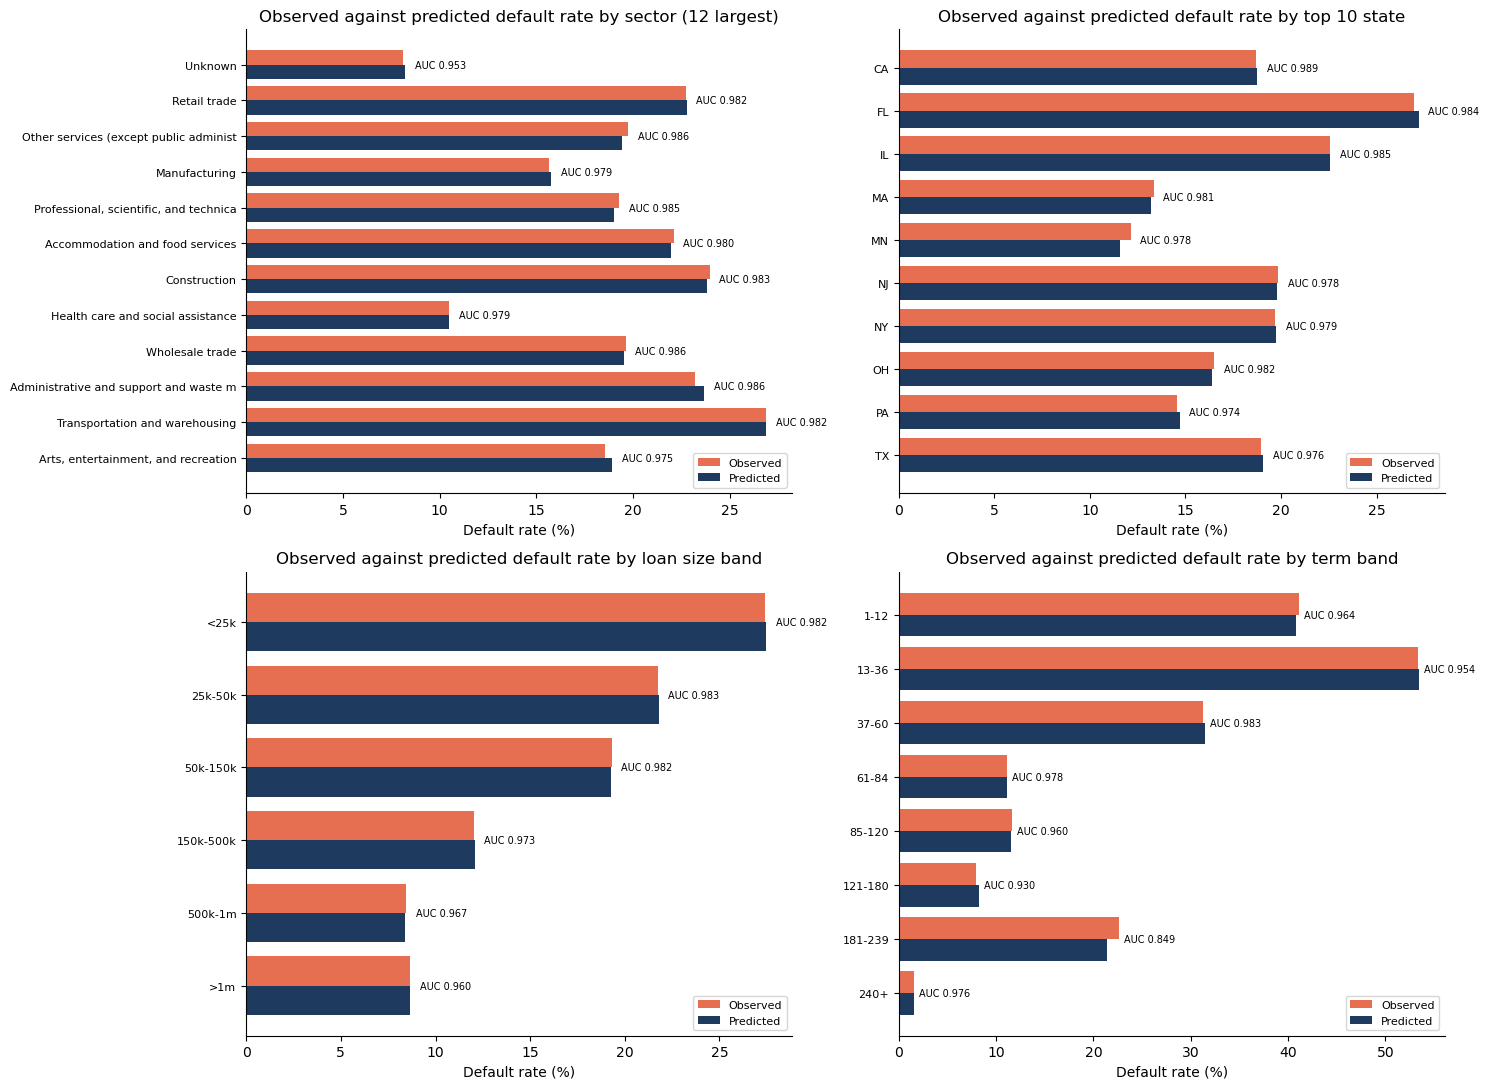

In [26]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
for ax, dim in zip(axes.ravel(), ["Sector", "Top 10 state", "Loan size band", "Term band"]):
    t = error_table[error_table["dimension"] == dim].copy()
    if dim == "Sector":
        t = t.sort_values("loans", ascending=False).head(12)
    y_pos = np.arange(len(t))
    ax.barh(y_pos - 0.2, 100 * t["observed_default_rate"], height=0.4, color=P["red"], label="Observed")
    ax.barh(y_pos + 0.2, 100 * t["mean_predicted_pd"], height=0.4, color=P["navy"], label="Predicted")
    for yp, (_, r) in zip(y_pos, t.iterrows()):
        ax.text(max(r["observed_default_rate"], r["mean_predicted_pd"]) * 100 + 0.5, yp, f"AUC {r['roc_auc']:.3f}",
                va="center", fontsize=7)
    ax.set_yticks(y_pos, [str(g)[:38] for g in t["group"]], fontsize=8)
    ax.invert_yaxis()
    ax.set_xlabel("Default rate (%)")
    ax.set_title(f"Observed against predicted default rate by {dim.lower()}" + (" (12 largest)" if dim == "Sector" else ""))
    ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
save_fig(fig, "fig05_error_analysis.png")
plt.show()

The model is strong and well calibrated in every group we checked. ROC-AUC is between 0.95 and 0.99 for every sector with more than 1,000 test loans, between 0.974 and 0.989 for the ten largest states, and between 0.960 and 0.983 for every loan size band; observed and predicted default rates agree within one percentage point in all of these groups. Three weaker spots stand out. Loans without an industry code (`Sector = Unknown`, mostly approved before 2001) have the lowest sector AUC (0.953) and a recall of only 0.767. Loans of 181 to 239 months have an AUC of 0.849 and a recall of 0.775: this band breaks the downward trend of default with term (22.6% default), and the model has fewer such loans to learn from. And recall is lower for long and large loans (0.610 for 240 months or more, 0.822 above USD 1 million), because their defaults are rare and their scores stay low. The table by approval year, saved in `docs/error_analysis.csv`, shows that without the calendar features the model underestimates the default rate of the few loans approved in 1988 or earlier (47.3% observed against 25.8% predicted) and slightly overestimates the earliest 1990s and the most recent years (by 2 to 4 points), which is the censoring pattern described in notebook 03.

### 9.1 The costliest false negatives

A false negative, an approved loan that is charged off, costs the bank far more than a false positive costs in forgone interest. We list the ten approved test loans with the largest loss and summarise how concentrated the losses are.

In [27]:
loss_test = ev.loss_if_default(D_test, G_test)
fn_mask = (p_test < THRESHOLD) & (y_test.to_numpy() == 1)
fp_mask = (p_test >= THRESHOLD) & (y_test.to_numpy() == 0)
fn = X_test.loc[fn_mask, ["LoanNr_ChkDgt", "DisbursementGross", "Portion", "Term", "Sector", "State", "NewExist",
                          "RevLineCr", "ApprovalFY"]].copy()
fn["pd"] = p_test[fn_mask]
fn["loss_usd"] = loss_test[fn_mask]
fn = fn.sort_values("loss_usd", ascending=False)
top_decile_share = fn["loss_usd"].head(max(1, len(fn) // 10)).sum() / fn["loss_usd"].sum()
print(f"False negatives: {fn_mask.sum():,} loans, loss {usd_m(fn['loss_usd'].sum())}; "
      f"the costliest 10% of them carry {top_decile_share:.1%} of that loss")
print(f"False positives: {fp_mask.sum():,} repaid loans not approved, forgone interest "
      f"{usd_m(ev.gain_if_repaid(D_test)[fp_mask].sum())}")
print(f"Median term of false negatives {fn['Term'].median():.0f} months against "
      f"{X_test.loc[y_test.to_numpy() == 1, 'Term'].median():.0f} for all charged-off test loans")
fn.head(10).round(3)

False negatives: 2,320 loans, loss USD 94.4 m; the costliest 10% of them carry 46.3% of that loss
False positives: 8,140 repaid loans not approved, forgone interest USD 90.2 m
Median term of false negatives 84 months against 50 for all charged-off test loans


,LoanNr_ChkDgt,DisbursementGross,Portion,Term,Sector,State,NewExist,RevLineCr,ApprovalFY,pd,loss_usd
42330,1332623009,1650000.0,0.303,78,Unknown,PA,New,N,1982,0.025,657525.0
284606,2982004003,1845000.0,0.406,167,Other services (except public administration),TX,Existing,N,1999,0.152,639754.0
469230,4547905003,3500000.0,0.750,66,Construction,UT,Existing,N,2011,0.045,612500.0
542328,5340484009,2000000.0,0.500,249,"Arts, entertainment, and recreation",OK,New,N,2002,0.062,600000.0
102237,1760554004,1700000.0,0.440,84,Unknown,MI,Existing,N,1998,0.044,561000.0
208834,2484004000,1550000.0,0.397,84,Wholesale trade,NY,Existing,N,1999,0.007,544825.0
407026,3951044006,1575000.0,0.476,293,Manufacturing,OH,Existing,N,2000,0.165,491282.0
220748,2570264004,1560000.0,0.481,284,Unknown,NE,New,N,1999,0.199,483054.0
398529,3860564003,1538000.0,0.488,264,Health care and social assistance,GA,Existing,N,2000,0.164,470905.0
471678,4567964000,1750000.0,0.571,296,Retail trade,TX,New,N,2001,0.185,462507.5


The costliest misses are large loans with a low guarantee: all ten are above USD 1.5 million, eight have a guarantee of 50% or less, and five of the ten have terms of 20 years or more, which the model reads as safe. Losses are concentrated: the costliest 10% of false negatives carry 46.3% of their total loss of USD 94.4 million. The false negatives have a median term of 84 months against 50 months for all charged-off test loans, so the model's errors come from loans that look like typical long, repaid loans. For a bank, the practical response is a size rule on top of the model: refer every loan above about USD 1 million with a guarantee below 50% to a credit officer, whatever its score. Against these 2,320 false negatives stand 8,140 false positives, repaid loans not approved automatically, which cost USD 90.2 million in forgone interest; with the cost matrix these two errors are roughly balanced at the chosen threshold, which is what an optimal threshold should achieve.

## 10. Temporal validation

The random split mixes loans from all years in both training and test, so the model has seen the same lending cycle it is tested on. A bank deploying the model will score loans from a period it has not seen. We therefore train the tuned pipeline (same settings and deployment features) on loans approved up to fiscal year 2005 and test it on loans approved from 2006 onwards, using `ApprovalFY` only to split the data. The threshold is the business threshold chosen above.

In [28]:
start = time.time()
early = df["ApprovalFY"] <= 2005
late = df["ApprovalFY"] >= 2006
temporal_pipe = clone(final_pipe)
temporal_pipe.fit(df.loc[early, FEATURES], df.loc[early, config.TARGET])
p_late = temporal_pipe.predict_proba(df.loc[late, FEATURES])[:, 1]
y_late = df.loc[late, config.TARGET].to_numpy()
TIMINGS["temporal_seconds"] = time.time() - start
t_metrics = ev.classification_metrics(y_late, p_late, THRESHOLD)
temporal = pd.DataFrame({
    "random split (test)": {"train_loans": len(X_train), "test_loans": len(X_test), "train_default_rate": y_train.mean(),
                            "test_default_rate": y_test.mean(), "mean_predicted_pd": p_test.mean(), **metrics_test},
    "temporal (train FY<=2005, test FY>=2006)": {"train_loans": int(early.sum()), "test_loans": int(late.sum()),
                            "train_default_rate": df.loc[early, config.TARGET].mean(),
                            "test_default_rate": y_late.mean(), "mean_predicted_pd": p_late.mean(), **t_metrics},
})
temporal["change"] = temporal.iloc[:, 1] - temporal.iloc[:, 0]
temporal.round(4).to_csv(config.DOCS_DIR / "temporal_validation.csv")
print("Saved docs/temporal_validation.csv")
temporal.round(4)

Saved docs/temporal_validation.csv


,random split (test),"temporal (train FY<=2005, test FY>=2006)",change
train_loans,716761.0000,652382.0000,-64379.0000
test_loans,179191.0000,243570.0000,64379.0000
train_default_rate,0.1756,0.1171,-0.0586
test_default_rate,0.1757,0.3325,0.1569
mean_predicted_pd,0.1757,0.2902,0.1144
roc_auc,0.9807,0.9676,-0.0130
pr_auc,0.9262,0.9308,0.0046
f1,0.8479,0.8819,0.0340
precision,0.7817,0.8478,0.0661
recall,0.9263,0.9189,-0.0074


Performance by approval year of the later loans shows where the drop comes from.

Saved docs/figures/fig05_temporal_validation.png


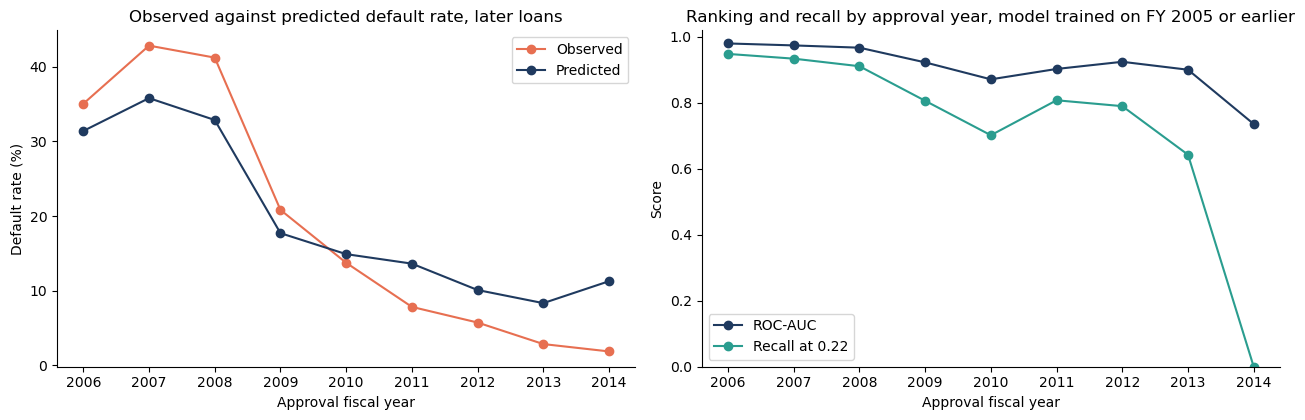

,loans,observed_default_rate,mean_predicted_pd,roc_auc,recall
year,,,,,
2006,75583.0,0.350,0.314,0.980,0.948
2007,71515.0,0.428,0.358,0.974,0.934
2008,39372.0,0.412,0.329,0.967,0.911
2009,19050.0,0.208,0.177,0.923,0.806
2010,16800.0,0.137,0.149,0.871,0.702
2011,12559.0,0.078,0.136,0.903,0.808
2012,5975.0,0.057,0.101,0.925,0.790
2013,2449.0,0.029,0.083,0.901,0.643
2014,267.0,0.019,0.113,0.736,0.000


In [29]:
late_df = pd.DataFrame({"year": df.loc[late, "ApprovalFY"].to_numpy(), "default": y_late, "pd": p_late})
by_year = late_df.groupby("year").apply(
    lambda g: pd.Series({"loans": len(g), "observed_default_rate": g["default"].mean(), "mean_predicted_pd": g["pd"].mean(),
                         "roc_auc": roc_auc_score(g["default"], g["pd"]) if g["default"].nunique() == 2 else np.nan,
                         "recall": recall_score(g["default"], (g["pd"] >= THRESHOLD).astype(int)) if g["default"].sum() else np.nan}),
    include_groups=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
axes[0].plot(by_year.index, 100 * by_year["observed_default_rate"], marker="o", color=P["red"], label="Observed")
axes[0].plot(by_year.index, 100 * by_year["mean_predicted_pd"], marker="o", color=P["navy"], label="Predicted")
axes[0].set_xlabel("Approval fiscal year")
axes[0].set_ylabel("Default rate (%)")
axes[0].set_title("Observed against predicted default rate, later loans")
axes[0].legend()
axes[1].plot(by_year.index, by_year["roc_auc"], marker="o", color=P["navy"], label="ROC-AUC")
axes[1].plot(by_year.index, by_year["recall"], marker="o", color=P["teal"], label=f"Recall at {THRESHOLD:.2f}")
axes[1].set_xlabel("Approval fiscal year")
axes[1].set_ylabel("Score")
axes[1].set_ylim(0, 1.02)
axes[1].set_title("Ranking and recall by approval year, model trained on FY 2005 or earlier")
axes[1].legend()
fig.tight_layout()
save_fig(fig, "fig05_temporal_validation.png")
plt.show()
by_year.round(3)

Trained only on loans approved up to fiscal year 2005, the model still ranks the 243,570 later loans well: ROC-AUC 0.9676 against 0.9807 on the random split, a drop of 0.013, and recall at the threshold of 0.22 falls only from 0.926 to 0.919. The larger change is in calibration. The later period has a default rate of 33.3% against 11.7% in the training years, because it contains the loans written before and during the financial crisis, and the model, which has never seen a downturn of that size, predicts 29.0% on average: it underestimates the 2006 to 2008 vintages by 4 to 8 percentage points and its Brier score almost doubles (0.0351 to 0.0656). For loans approved from 2011 onwards the opposite happens: the model predicts 8 to 14% while the observed rate falls to 2 to 8%, because these loans had too little time to default before the data was extracted (right-censoring), and the AUC for the years 2010 to 2013 drops to between 0.87 and 0.93. The ranking of borrowers is therefore stable over time, but the level of risk moves with the economy. For monitoring this means that a bank should track calibration by approval quarter, compare predicted and observed default rates only on loans that have had time to mature, recalibrate the probability scale when the economic cycle turns, and use the Recession switch in the app as a stress test rather than trusting the base-case probability in a downturn.

## 11. Saving the model artefacts

We save the artefacts listed in section 11 of the brief. `final_model.joblib` is the full pipeline (bank encoder and column transformer, then the classifier), fitted on the training split; it takes a DataFrame with the columns of `fe.FEATURE_COLUMNS` (extra columns are ignored) and `predict_proba(X)[:, 1]` returns the probability of default. The LightGBM inside it is set to one thread, which is faster for the single loans the app scores. The SHAP background is a stratified sample of 2,000 training loans in the preprocessed form the explainer works on.

In [30]:
final_pipe.set_params(**({"clf__estimator__n_jobs": 1} if use_calibration else {"clf__n_jobs": 1}))
joblib.dump(final_pipe, config.FINAL_MODEL_PATH, compress=3)
joblib.dump(comparison_pipe, config.MODELS_DIR / "comparison_model.joblib", compress=3)

# SHAP background: 2,000 stratified training loans, preprocessed
X_bg, y_bg = md.stratified_subsample(X_train, y_train, 2_000)
background = pd.DataFrame(prep.transform(X_bg[FEATURES]), columns=feature_names)
background.to_parquet(config.MODELS_DIR / "shap_background.parquet", index=False)
shap_global.to_csv(config.MODELS_DIR / "shap_global.csv", index=False)

comparison_csv = pd.read_csv(config.DOCS_DIR / "model_comparison.csv")
bm = policy.loc[model_key]
blr = policy.loc[lr_key]
metadata = {
    "model_name": "LightGBM (tuned" + (", isotonic calibration)" if use_calibration else ")"),
    "library_versions": {"python": sys.version.split()[0], "scikit-learn": sklearn.__version__,
                         "lightgbm": lightgbm.__version__, "shap": shap.__version__, "pandas": pd.__version__,
                         "numpy": np.__version__, "scipy": scipy.__version__, "joblib": joblib.__version__,
                         "matplotlib": matplotlib.__version__},
    "trained_on": date.today().isoformat(),
    "n_train": int(len(X_train)),
    "n_test": int(len(X_test)),
    "features": list(FEATURES),
    "categorical_features": list(CAT),
    "numeric_features": list(NUM),
    "bank_column": fe.BANK_COLUMN,
    "bank_features": list(fe.BANK_FEATURES),
    "excluded_calendar_features": list(fe.CALENDAR_FEATURES),
    "preprocessed_feature_names": feature_names,
    "hyperparameters": best_lgbm,
    "metrics_test": {k: round(v, 5) for k, v in metrics_test.items()},
    "metrics_cv": {"roc_auc_mean": round(float(lgbm_tuned_cv[0]), 5), "roc_auc_std": round(float(lgbm_tuned_cv[1]), 5),
                   "n_folds": 3, "source": "RandomizedSearchCV best candidate on the training split"},
    "threshold": float(THRESHOLD),
    "risk_bands": RISK_BANDS,
    "decision_rule": DECISION_RULE,
    "cost_assumptions": {"NET_INTEREST_MARGIN": config.NET_INTEREST_MARGIN, "LOSS_GIVEN_DEFAULT": config.LOSS_GIVEN_DEFAULT,
                         "WORKOUT_COST_RATE": config.WORKOUT_COST_RATE, "MIN_APPROVAL_RATE": config.MIN_APPROVAL_RATE,
                         "loss_base": "LOSS_GIVEN_DEFAULT x DisbursementGross x (1 - Portion) + WORKOUT_COST_RATE x DisbursementGross",
                         "gain_base": "NET_INTEREST_MARGIN x DisbursementGross"},
    "business_results": {
        "data": "test split, realised outcomes",
        "approval_rate": round(float(bm.approval_rate), 5),
        "expected_default_rate_approved": round(float(bm.expected_default_rate_approved), 5),
        "observed_default_rate_approved": round(float(bm.default_rate_approved), 5),
        "net_value_model": round(float(bm.net_value), 2),
        "net_value_approve_all": round(float(base_value), 2),
        "net_value_comparison_model": round(float(blr.net_value), 2),
        "comparison_model_threshold": float(THRESHOLD_LR),
        "comparison_model_approval_rate": round(float(blr.approval_rate), 5),
        "chargeoff_loss_model": round(float(bm.chargeoff_loss), 2),
        "chargeoff_loss_approve_all": round(float(base_loss), 2),
        "chargeoff_loss_comparison_model": round(float(blr.chargeoff_loss), 2),
        "loss_avoided": round(float(bm.loss_avoided), 2),
        "loss_reduction_pct": round(float(bm.loss_reduction_pct), 3),
        "loss_reduction_pct_comparison_model": round(float(blr.loss_reduction_pct), 3),
    },
    "comparison_table": json.loads(comparison_csv.to_json(orient="records")),
    "before_after_tuning": json.loads(before_after.round(5).to_json(orient="records")),
    "temporal_validation": {
        "train": "ApprovalFY <= 2005", "test": "ApprovalFY >= 2006",
        "n_train": int(early.sum()), "n_test": int(late.sum()),
        "roc_auc": round(t_metrics["roc_auc"], 5), "pr_auc": round(t_metrics["pr_auc"], 5),
        "recall": round(t_metrics["recall"], 5), "precision": round(t_metrics["precision"], 5),
        "brier": round(t_metrics["brier"], 5),
        "test_default_rate": round(float(y_late.mean()), 5), "mean_predicted_pd": round(float(p_late.mean()), 5),
        "roc_auc_drop_vs_random_split": round(metrics_test["roc_auc"] - t_metrics["roc_auc"], 5),
        "recall_drop_vs_random_split": round(metrics_test["recall"] - t_metrics["recall"], 5),
    },
    "top_features": [{"feature": r.feature, "importance": round(float(r.mean_abs_shap), 5)}
                     for r in shap_global.head(15).itertuples()],
    "shap": {"explainer": "shap.TreeExplainer on the LightGBM step", "output": "log-odds of default",
             "expected_value": float(np.mean(sv.base_values)), "background": "models/shap_background.parquet"},
}
with open(config.MODEL_METADATA_PATH, "w") as f:
    json.dump(metadata, f, indent=2)

required = ["model_name", "library_versions", "trained_on", "n_train", "n_test", "features", "categorical_features",
            "numeric_features", "metrics_test", "metrics_cv", "threshold", "risk_bands", "decision_rule",
            "cost_assumptions", "business_results", "comparison_table", "before_after_tuning", "temporal_validation",
            "top_features"]
assert all(k in metadata for k in required)
sizes = {p.name: p.stat().st_size / 1e6 for p in sorted(config.MODELS_DIR.iterdir()) if p.is_file()}
for name, mb in sizes.items():
    print(f"models/{name}: {mb:.2f} MB")
print(f"Total size of models/: {sum(sizes.values()):.2f} MB")
assert sum(sizes.values()) < 100

models/comparison_model.joblib: 0.24 MB
models/feature_schema.json: 0.20 MB
models/final_model.joblib: 3.25 MB
models/model_metadata.json: 0.01 MB
models/shap_background.parquet: 0.08 MB
models/shap_global.csv: 0.00 MB
Total size of models/: 3.78 MB


## 12. Evaluation summary and model card

The key results are written to `docs/evaluation_summary.md` for the report, and the model card to `docs/model_card.md` for the app and for anyone who has to decide whether the model may be used. Every number in both files comes from the variables computed above.

In [31]:
cmp_rows = comparison_csv.set_index("model")
tb = before_after.set_index(["model", "version"])
top10 = ", ".join(shap_global["feature"].head(10))
sens = pd.read_csv(config.DOCS_DIR / "feature_set_sensitivity.csv").set_index("model")
s_full = sens.loc["A. Full feature set of notebook 03"]
s_dep = sens.loc["B. Deployment feature set"]
s_noterm = sens.loc["C. Deployment set without TermYears and RealEstate"]
worst_sector = error_table[(error_table["dimension"] == "Sector") & (error_table["loans"] >= 1000)].sort_values("roc_auc").iloc[0]
tv = metadata["temporal_validation"]

summary = f"""# Evaluation summary

Author: Mansoor Mohamed Mansoor Saeed Alwahedi
Produced by: notebooks/04_model_selection.ipynb and notebooks/05_tuning_evaluation.ipynb
Data: 716,761 training and 179,191 test loans (stratified 80/20 split of notebook 03, default rate 17.56%); deployment feature set of {len(FEATURES)} input columns.

1. Deployment feature set. Removing ApprovalYear, ApprovalMonth and DisbursementLagDays, which cannot be valued for a new application and partly encode right-censoring, lowers default LightGBM's 5-fold CV ROC-AUC from {s_full.cv_roc_auc_mean:.4f} to {s_dep.cv_roc_auc_mean:.4f} and CV PR-AUC from {s_full.cv_pr_auc_mean:.4f} to {s_dep.cv_pr_auc_mean:.4f}. Every model after this point uses the deployment set.
2. Term sensitivity. Without TermYears and RealEstate the CV ROC-AUC falls to {s_noterm.cv_roc_auc_mean:.4f} and PR-AUC to {s_noterm.cv_pr_auc_mean:.4f}. Term is agreed at approval and is kept, but much of the performance rests on it (see limitations in docs/model_card.md).
3. Model comparison (5-fold CV ROC-AUC, deployment features): dummy {cmp_rows.loc['Dummy (prior)', 'cv_roc_auc_mean']:.4f}, logistic regression {cmp_rows.loc['Logistic regression', 'cv_roc_auc_mean']:.4f}, random forest {cmp_rows.loc['Random forest', 'cv_roc_auc_mean']:.4f} (200,000-loan subsample), histogram gradient boosting {cmp_rows.loc['Hist gradient boosting', 'cv_roc_auc_mean']:.4f}, LightGBM {cmp_rows.loc['LightGBM', 'cv_roc_auc_mean']:.4f}. LightGBM was chosen; the table is in docs/model_comparison.csv.
4. Tuning. RandomizedSearchCV (25 candidates, 3 folds) raised LightGBM's 3-fold CV ROC-AUC from {lgbm_default_cv[0]:.4f} to {lgbm_tuned_cv[0]:.4f} and its test ROC-AUC from {tb.loc[('LightGBM', 'default'), 'test_roc_auc']:.4f} to {tb.loc[('LightGBM', 'tuned'), 'test_roc_auc']:.4f} (PR-AUC {tb.loc[('LightGBM', 'default'), 'test_pr_auc']:.4f} to {tb.loc[('LightGBM', 'tuned'), 'test_pr_auc']:.4f}). The logistic regression's best C was {best_C} (test ROC-AUC {tb.loc[('Logistic regression', 'tuned'), 'test_roc_auc']:.4f}); the tuned random forest reached {tb.loc[('Random forest', 'tuned'), 'test_roc_auc']:.4f}. Details in docs/tuning_before_after.csv.
5. Final test performance of the tuned LightGBM: ROC-AUC {metrics_test['roc_auc']:.4f}, PR-AUC {metrics_test['pr_auc']:.4f}, Brier score {metrics_test['brier']:.4f}; at the business threshold of {THRESHOLD:.2f}, recall on defaults {metrics_test['recall']:.4f}, precision {metrics_test['precision']:.4f}, F1 {metrics_test['f1']:.4f}, accuracy {metrics_test['accuracy']:.4f}, balanced accuracy {metrics_test['balanced_accuracy']:.4f}. SMART objective 1 (ROC-AUC at least 0.80, recall at least 0.70) is {'met' if metrics_test['roc_auc'] >= 0.80 and metrics_test['recall'] >= 0.70 else 'not met'}.
6. Calibration. Isotonic calibration changed the test Brier score from {calib.loc[0, 'test_brier']:.5f} to {calib.loc[1, 'test_brier']:.5f} and ROC-AUC from {calib.loc[0, 'test_roc_auc']:.4f} to {calib.loc[1, 'test_roc_auc']:.4f}; it was {'adopted' if use_calibration else 'not adopted'} under the rule fixed beforehand (at least 1% lower Brier, at most 0.001 lower AUC).
7. Threshold. Chosen on out-of-fold training predictions as the threshold with the highest net value among those approving at least 75% of loans: {THRESHOLD:.2f}. On the test split it approves {bm.approval_rate:.1%} of loans, with an observed default rate of {bm.default_rate_approved:.2%} among approved loans (expected from the model {bm.expected_default_rate_approved:.2%}).
8. Business value on the test split (realised outcomes): net value {usd_m(bm.net_value)} for the LightGBM policy against {usd_m(base_value)} for approve-all and {usd_m(blr.net_value)} for the logistic comparison model at its own threshold of {THRESHOLD_LR:.2f} (approval rate {blr.approval_rate:.1%}).
9. SMART objective 2. Charge-off loss falls from {usd_m(base_loss)} (approve-all) to {usd_m(bm.chargeoff_loss)}, a loss avoided of {usd_m(bm.loss_avoided)} or {bm.loss_reduction_pct:.1f}% (target at least 25% at an approval rate of at least 75%: {'met' if bm.loss_reduction_pct >= 25 and bm.approval_rate >= 0.75 else 'not met'}). The logistic model reduces the loss by {blr.loss_reduction_pct:.1f}%.
10. Risk bands: Low below {LOW_CUT:.2f}, Medium {LOW_CUT:.2f} to {THRESHOLD:.2f}, High {THRESHOLD:.2f} to {HIGH_CUT:.2f}, Very high {HIGH_CUT:.2f} or more. Observed test default rates {', '.join(f'{b} {r:.1%}' for b, r in bands['default_rate'].items())}; shares of loans {', '.join(f'{b} {s:.1%}' for b, s in bands['share_of_loans'].items())}.
11. Explainability. The ten features with the highest mean absolute SHAP value are {top10}.
12. Error analysis. Among sectors with at least 1,000 test loans the lowest ROC-AUC is {worst_sector['roc_auc']:.3f} ({worst_sector['group']}). False negatives: {fn_mask.sum():,} approved loans that defaulted, with a loss of {usd_m(fn['loss_usd'].sum())}; the costliest 10% of them carry {top_decile_share:.1%} of that loss.
13. Temporal validation (train FY 2005 or earlier, {tv['n_train']:,} loans; test FY 2006 or later, {tv['n_test']:,} loans): ROC-AUC {tv['roc_auc']:.4f} ({tv['roc_auc_drop_vs_random_split']:.4f} below the random split), recall {tv['recall']:.4f} ({tv['recall_drop_vs_random_split']:.4f} below), observed default rate {tv['test_default_rate']:.2%} against a mean prediction of {tv['mean_predicted_pd']:.2%}.
14. Artefacts. models/final_model.joblib is {sizes['final_model.joblib']:.2f} MB and the whole models/ folder {sum(sizes.values()):.2f} MB, well under the 100 MB limit.

Tables: docs/model_comparison.csv, docs/feature_set_sensitivity.csv, docs/class_weight_comparison.csv, docs/tuning_before_after.csv, docs/threshold_sweep.csv, docs/policy_comparison.csv, docs/risk_bands.csv, docs/error_analysis.csv, docs/temporal_validation.csv, docs/permutation_importance_logistic.csv. Figures: docs/figures/fig04_*.png and docs/figures/fig05_*.png.
"""
(config.DOCS_DIR / "evaluation_summary.md").write_text(summary)
print(summary)

# Evaluation summary

Author: Mansoor Mohamed Mansoor Saeed Alwahedi
Produced by: notebooks/04_model_selection.ipynb and notebooks/05_tuning_evaluation.ipynb
Data: 716,761 training and 179,191 test loans (stratified 80/20 split of notebook 03, default rate 17.56%); deployment feature set of 23 input columns.

1. Deployment feature set. Removing ApprovalYear, ApprovalMonth and DisbursementLagDays, which cannot be valued for a new application and partly encode right-censoring, lowers default LightGBM's 5-fold CV ROC-AUC from 0.9801 to 0.9748 and CV PR-AUC from 0.9241 to 0.9081. Every model after this point uses the deployment set.
2. Term sensitivity. Without TermYears and RealEstate the CV ROC-AUC falls to 0.8379 and PR-AUC to 0.5799. Term is agreed at approval and is kept, but much of the performance rests on it (see limitations in docs/model_card.md).
3. Model comparison (5-fold CV ROC-AUC, deployment features): dummy 0.5000, logistic regression 0.8634, random forest 0.9551 (200,000-l

The model card follows the usual structure: what the model is for and not for, what it was trained on, how well it performs, how its output is turned into a decision, what its limits are and how it should be monitored.

In [32]:
band_lines = "\n".join(
    f"| {b} | {r.pd_min:.2f} to {r.pd_max:.2f} | {r.decision} | {r.share_of_loans:.1%} | {r.default_rate:.1%} |"
    for b, r in bands.iterrows())
feature_lines = "\n".join(f"| `{f}` | {fe.FEATURE_INFO[f][0]} |" for f in FEATURES)
top_lines = "\n".join(f"| {i + 1} | `{r.feature}` | {r.mean_abs_shap:.3f} |" for i, r in shap_global.head(10).iterrows())
state_rows = error_table[error_table["dimension"] == "Top 10 state"]

card = f"""# Model card: CreditLens SME default-risk model

Owner: Mansoor Mohamed Mansoor Saeed Alwahedi (modelling and evaluation), CreditLens team, HCT CDS4003
Model file: models/final_model.joblib (scikit-learn Pipeline, {sizes['final_model.joblib']:.2f} MB). Metadata: models/model_metadata.json.
Version date: {date.today().isoformat()}

## Intended use

The model estimates the probability that a guaranteed SME loan will be charged off, from information available when the credit decision is made. It is a decision-support tool for a bank's SME credit desk: it ranks applications, places them in a risk band, suggests approve, refer or decline, and shows the expected value of the loan under the bank's cost assumptions together with the features that drove the score. The final decision stays with a credit officer. The model is not intended for consumer lending, for loans outside a guarantee scheme, for setting interest rates, or as the only basis for declining an applicant.

## Training data

US Small Business Administration 7(a) loans approved between 1962 and 2014 (Li, Mickel and Taylor, 2018, via Kaggle, CC BY-SA 4.0), cleaned in notebook 02 to 895,952 loans with a known outcome. The model was trained on the stratified 80% training split ({len(X_train):,} loans, default rate {y_train.mean():.2%}) and tested on the remaining {len(X_test):,} loans. Default means the loan status is charged off. Data are from the United States; using the model for a UAE bank would require validation and recalibration on local loans before any live use.

## Features

{len(FEATURES)} inputs: {len(NUM)} numeric (including 0/1 indicators), {len(CAT)} categorical and the lending bank, which the pipeline turns into BankSize and an out-of-fold BankDefaultRate learned from training loans only. ApprovalYear, ApprovalMonth and DisbursementLagDays were removed because they cannot be valued for a new application and partly measure right-censoring (notebook 04). Leakage columns (ChgOffDate, ChgOffPrinGr, BalanceGross), identifiers, City and Zip are never used.

| Feature | Meaning |
|---|---|
{feature_lines}

## Performance (test split, {len(X_test):,} loans)

| Metric | Value |
|---|---|
| ROC-AUC | {metrics_test['roc_auc']:.4f} |
| PR-AUC | {metrics_test['pr_auc']:.4f} |
| Brier score | {metrics_test['brier']:.4f} |
| Recall on defaults at threshold {THRESHOLD:.2f} | {metrics_test['recall']:.4f} |
| Precision at threshold | {metrics_test['precision']:.4f} |
| F1 at threshold | {metrics_test['f1']:.4f} |
| Accuracy / balanced accuracy | {metrics_test['accuracy']:.4f} / {metrics_test['balanced_accuracy']:.4f} |
| 3-fold CV ROC-AUC (training split) | {lgbm_tuned_cv[0]:.4f} (sd {lgbm_tuned_cv[1]:.4f}) |
| Temporal validation ROC-AUC (train FY up to 2005, test FY 2006 on) | {tv['roc_auc']:.4f} |
| Temporal validation recall | {tv['recall']:.4f} |

The interpretable comparison model (logistic regression, C = {best_C}) reaches a test ROC-AUC of {metrics_test_lr['roc_auc']:.4f}.

Most important features by mean absolute SHAP value (log-odds):

| Rank | Feature | Mean absolute SHAP |
|---|---|---|
{top_lines}

## Threshold, risk bands and decision rule

Cost assumptions: a repaid loan earns {config.NET_INTEREST_MARGIN:.0%} of the disbursed amount; a charged-off loan loses {config.LOSS_GIVEN_DEFAULT:.0%} of the unguaranteed principal plus a {config.WORKOUT_COST_RATE:.0%} workout cost; a declined loan earns and loses nothing. The threshold of {THRESHOLD:.2f} maximises net value on out-of-fold training predictions subject to an approval rate of at least {config.MIN_APPROVAL_RATE:.0%}.

{DECISION_RULE}

| Band | Probability of default | Decision | Share of test loans | Observed default rate |
|---|---|---|---|---|
{band_lines}

On the test split this policy approves {bm.approval_rate:.1%} of loans, earns a realised net value of {usd_m(bm.net_value)} against {usd_m(base_value)} for approving every loan, and cuts charge-off loss by {bm.loss_reduction_pct:.1f}%.

## Limitations

* Loan term dominates. Without TermYears and RealEstate the cross-validated ROC-AUC falls from {s_dep.cv_roc_auc_mean:.3f} to {s_noterm.cv_roc_auc_mean:.3f}. Term is agreed at approval, but we cannot rule out that for some charged-off loans the recorded term was shortened after the event; if so, part of the measured performance would not be available in live use.
* Right-censoring and drift. Loans approved shortly before 2014 had little time to default, and the default rate moved from about 3% to 44% across approval years. Trained on loans up to FY 2005, the model scores later loans with ROC-AUC {tv['roc_auc']:.3f} and predicts a mean default rate of {tv['mean_predicted_pd']:.1%} against {tv['test_default_rate']:.1%} observed.
* The data are US loans from 1962 to 2014 under SBA programme rules; guarantee shares, lender behaviour and the economy differ in the UAE and in 2026.
* The cost matrix is a simplification: it ignores the time value of money, partial recoveries beyond the fixed loss rate and the value of referred loans that are approved after review.
* Recession is a scenario input: the model learned it from the 2007 to 2009 downturn, so a different kind of downturn may affect loans differently.

## Ethics and fairness

The data contain no personal characteristics of the owners (no gender, age, ethnicity or nationality), so the model cannot use them directly. Borrower state, bank state, sector and urban or rural location are used, and geography can act as a proxy for protected characteristics or penalise whole regions; across the ten largest states the test ROC-AUC ranges from {state_rows['roc_auc'].min():.3f} to {state_rows['roc_auc'].max():.3f} and the observed default rate from {state_rows['observed_default_rate'].min():.1%} to {state_rows['observed_default_rate'].max():.1%}. BankDefaultRate means that a borrower's score depends on the lender's past book, which the borrower does not control. New businesses and small loans receive higher scores on average, which could reduce access to credit for the firms a guarantee scheme exists to help. We therefore recommend that the model is used to refer rather than automatically decline borderline cases, that declines are reviewed by a person and explained with the SHAP drivers, and that approval rates are monitored by region, sector and business age.

## Monitoring plan

* Monthly: distribution of the input features and of the predicted probabilities against the training data (population stability index above 0.25 triggers a review), approval rate and band mix.
* Quarterly: observed default rate against predicted probability by approval quarter for loans with at least 24 months of history, ROC-AUC and recall on matured loans, and the same figures by state, sector and loan size.
* Annually, or when a monitored ROC-AUC falls by more than 0.05 or calibration error exceeds 5 percentage points in any band: retrain on recent matured loans, re-choose the threshold with the bank's current cost assumptions and repeat the temporal validation.
* Any change to the guarantee programme, the cost assumptions or the feature definitions requires a new model version and an updated model card.
"""
(config.DOCS_DIR / "model_card.md").write_text(card)
print(f"Saved docs/model_card.md ({len(card.split()):,} words)")

Saved docs/model_card.md (1,347 words)


All artefacts of section 11 of the brief are saved. The final model file is a little over 3 MB and the whole `models/` folder under 4 MB, far below the 100 MB limit, so the app can load it in well under a second. The evaluation summary and the model card above repeat the key numbers of this notebook for the report and the app.

## 13. Run time

In [33]:
TIMINGS["total_minutes"] = (time.time() - NOTEBOOK_START) / 60
print({k: round(v, 2) for k, v in TIMINGS.items()})

{'lightgbm_search_minutes': 33.1, 'logistic_search_minutes': 2.08, 'random_forest_search_minutes': 9.79, 'refit_minutes': 8.32, 'calibration_minutes': 2.06, 'out_of_fold_minutes': 2.46, 'shap_seconds': 24.46, 'permutation_seconds': 10.87, 'temporal_seconds': 49.61, 'total_minutes': 59.66}


## 14. Check the saved model as the app will use it

The last check runs in a fresh Python process, as the Streamlit app will. It reads five loans from the raw 5,000-row sample, passes them through the cleaning functions of `src/cleaning.py` (the outlier caps and medians are fitted on the sample, since a handful of loans cannot supply them) and through `fe.build_features()`, loads `final_model.joblib` and scores them with `predict_proba`.

In [34]:
check_script = """
import sys, time, json
sys.path.insert(0, ".")
import joblib
import pandas as pd
from src import config, cleaning as cl, features as fe

start = time.time()
raw = pd.read_csv(config.SAMPLE_DATA_PATH)
step = cl.apply_logical_checks(cl.clean_codes(cl.add_target(cl.parse_types(raw))))
_, params = cl.handle_outliers(step)                # caps and medians from the 5,000-row sample
five, _ = cl.handle_outliers(step.head(5), params)  # five loans cleaned with those values
five = cl.fill_missing_categoricals(five)
X = fe.build_features(five)[fe.FEATURE_COLUMNS]
model = joblib.load(config.FINAL_MODEL_PATH)
meta = json.load(open(config.MODEL_METADATA_PATH))
p = model.predict_proba(X)[:, 1]
assert p.shape == (5,) and ((p >= 0) & (p <= 1)).all()
print("Columns passed:", X.shape[1], "| model type:", type(model).__name__, "| last step:", type(model[-1]).__name__)
for loan, prob in zip(five["LoanNr_ChkDgt"], p):
    decision = "approve" if prob < meta["threshold"] else "refer or decline"
    print(f"Loan {loan}: probability of default {prob:.4f} -> {decision}")
print(f"Loaded and scored in {time.time() - start:.2f} s")
"""
result = subprocess.run([sys.executable, "-c", check_script], cwd=ROOT, capture_output=True, text=True)
print(result.stdout)
if result.returncode != 0:
    print(result.stderr)
assert result.returncode == 0

Columns passed: 26 | model type: Pipeline | last step: LGBMClassifier
Loan 6106063001: probability of default 0.0103 -> approve
Loan 8984934001: probability of default 0.0077 -> approve
Loan 8048893003: probability of default 0.0027 -> approve
Loan 4005365002: probability of default 0.0348 -> approve
Loan 2518374005: probability of default 0.0042 -> approve
Loaded and scored in 0.75 s

